# Лабораторна робота №2: Логістична регресія та федеративне навчання

**Мета:** самому написати багатокласову (softmax) логістичну регресію на `numpy`, навчити її звичайним
(централізованим) способом, а потім змоделювати федеративне навчання (federated learning): дані розкидані
між кількома клієнтами, сервер бачить лише ваги моделей, а не самі дані.

**Датасет:** Dry Bean Dataset (UCI / Kaggle), файл `data/Dry_Bean_Dataset.xlsx`.
13 611 зерен квасолі, 16 числових ознак форми зерна (площа, периметр, осі еліпса, коефіцієнти форми),
цільова змінна `Class` - один із 7 сортів.

**План роботи:**
1. Дослідження даних (EDA), розбиття на Global Test / Global Validation / FL Train Pool, відбір ознак, масштабування
2. Softmax-регресія на `numpy` + перевірка градієнтів
3. Централізована модель: підбір learning rate, розміру батчу, Ridge-регуляризації
4. Розподіл даних між клієнтами: IID та Non-IID (Діріхле)
5. Симуляція FedAvg
6. Порівняння локальних, глобальної та централізованої моделей + обов'язкові експерименти ($\alpha$ та E)
7. Додатковий експеримент А: кількість клієнтів
8. Теоретичні питання та висновки

## 0. Бібліотеки

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             log_loss, confusion_matrix)

SEED = 42
np.random.seed(SEED)

---
## 1. Етап 1. Дослідження даних та попередня обробка

### 1.1 Первинний аналіз

In [2]:
df = pd.read_excel('data/Dry_Bean_Dataset.xlsx')
print(df.shape)
df.head()

(13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [4]:
print('Missing values in the whole table:', df.isna().sum().sum())
print('Fully duplicated rows:', df.duplicated().sum())

Missing values in the whole table: 0
Fully duplicated rows: 68


**Висновок.** Таблиця має 13 611 рядків і 17 колонок: 16 числових ознак (14 дробових, 2 цілих - `Area` і `ConvexArea`
у пікселях) і текстову ціль `Class`. Пропусків **немає**, тому заповнювати нічого не треба.
Але є **68 повністю однакових рядків** (0.5%). Їх видаляємо **до** розбиття.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

Shape after dropping duplicates: (13543, 17)


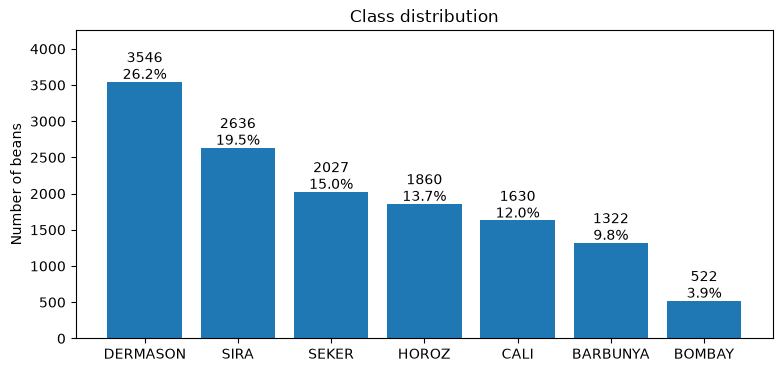

In [6]:
counts = df['Class'].value_counts()
plt.figure(figsize=(9, 4))
plt.bar(counts.index, counts.values)
for i, value in enumerate(counts.values):
    plt.text(i, value + 40, f'{value}\n{value / len(df):.1%}', ha='center')
plt.ylim(0, counts.max() * 1.2)
plt.ylabel('Number of beans')
plt.title('Class distribution')
plt.show()

**Висновок.** Класи **незбалансовані**: найбільший `DERMASON` - близько 26% зерен, найменший `BOMBAY` - менше 4%
(майже в 7 разів менше). Це означає, що звичайна accuracy буде більше залежати від великих класів, тому
поряд з нею дивимося на macro-F1 і balanced accuracy, де кожен клас важить однаково. Розбиття робимо
стратифікованим, щоб маленький `BOMBAY` був у всіх частинах у тій самій пропорції.

In [7]:
df.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000
Perimeter,13543.0,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700
MajorAxisLength,13543.0,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602
MinorAxisLength,13543.0,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985
AspectRation,13543.0,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303
Eccentricity,13543.0,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114
ConvexArea,13543.0,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000
EquivDiameter,13543.0,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744
Extent,13543.0,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662
Solidity,13543.0,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


**Висновок.** Масштаби ознак відрізняються дуже сильно: `Area` - від 20 420 до 254 616, а `ShapeFactor2` - близько 0.0017, `Solidity` має std лише 0.0047. Тобто різниця в масштабі - порядку $10^8$ разів. Максимум `Area` (254 616) набагато більший за 75-й перцентиль (61 382) - це не помилки, а найбільші зерна (сорт `BOMBAY`), тому викиди не видаляємо.

### 1.2 Розбиття на Global Test, Global Validation та FL Train Pool

Ділимо дані до будь-якого аналізу, який щось "вчить" з даних (кореляції для відбору ознак, середні для масштабування).
Обидва розбиття стратифіковані (stratified) за класом, щоб пропорції сортів були однакові в усіх частинах:

- **Global Test** - 15%, лежить на сервері, використовуємо тільки один раз для фінальної оцінки;
- **Global Validation** - 15%, лежить на сервері, для підбору гіперпараметрів і моніторингу FL;
- **FL Train Pool** - решта 70%, саме її потім роздамо клієнтам.

In [8]:
X_all = df.drop(columns='Class')
y_all = df['Class']

# first cut off the test set, then validation from what is left
X_rest, X_test_raw, y_rest, y_test_str = train_test_split(
    X_all, y_all, test_size=0.15, stratify=y_all, random_state=SEED)
X_pool_raw, X_val_raw, y_pool_str, y_val_str = train_test_split(
    X_rest, y_rest, test_size=0.15 / 0.85, stratify=y_rest, random_state=SEED)

print('FL Train Pool:    ', X_pool_raw.shape)
print('Global Validation:', X_val_raw.shape)
print('Global Test:      ', X_test_raw.shape)

# the three parts must not share any row
assert len(set(X_pool_raw.index) & set(X_val_raw.index)) == 0
assert len(set(X_pool_raw.index) & set(X_test_raw.index)) == 0
assert len(set(X_val_raw.index) & set(X_test_raw.index)) == 0
assert len(X_pool_raw) + len(X_val_raw) + len(X_test_raw) == len(df)

pd.DataFrame({
    'FL Train Pool': y_pool_str.value_counts(normalize=True),
    'Global Validation': y_val_str.value_counts(normalize=True),
    'Global Test': y_test_str.value_counts(normalize=True),
}).round(3)

FL Train Pool:     (9479, 16)
Global Validation: (2032, 16)
Global Test:       (2032, 16)


,FL Train Pool,Global Validation,Global Test
Class,,,
DERMASON,0.262,0.262,0.262
SIRA,0.195,0.195,0.195
SEKER,0.150,0.150,0.150
HOROZ,0.137,0.137,0.137
CALI,0.120,0.121,0.121
BARBUNYA,0.098,0.097,0.097
BOMBAY,0.039,0.038,0.038


Частки класів у трьох частинах збігаються до третього знаку - стратифікація спрацювала.

**Питання: чому розбиття потрібно робити до масштабування, кодування та інших операцій, які навчаються на даних? Що таке Data Leakage?**

Витік даних (data leakage) - це коли в процес навчання якимось шляхом потрапляє інформація з даних, на яких ми потім оцінюємо модель. Найчастіше це стається не в самій моделі, а в підготовці даних. Наприклад, якщо порахувати середнє і стандартне відхилення по всьому датасету, а вже потім розбити його, то тест "підмішався" в ці числа.
Так само з відбором ознак: якщо обирати ознаки за кореляціями на всіх даних, ми частково підганяємо вибір під тест.
У результаті метрика на тесті виходить кращою, ніж буде на справді нових даних. Тому правило просте:
спочатку ділимо, потім усе, що щось рахує з даних, рахуємо тільки на тренувальній частині (тут - FL Train Pool), а до Validation і Test лише застосовуємо вже пораховані параметри.

### 1.3 Відбір ознак (тільки на FL Train Pool)

Спочатку подивимося на кореляції ознак між собою - чи немає ознак, які майже дублюють одна одну
(мультиколінеарність, multicollinearity).

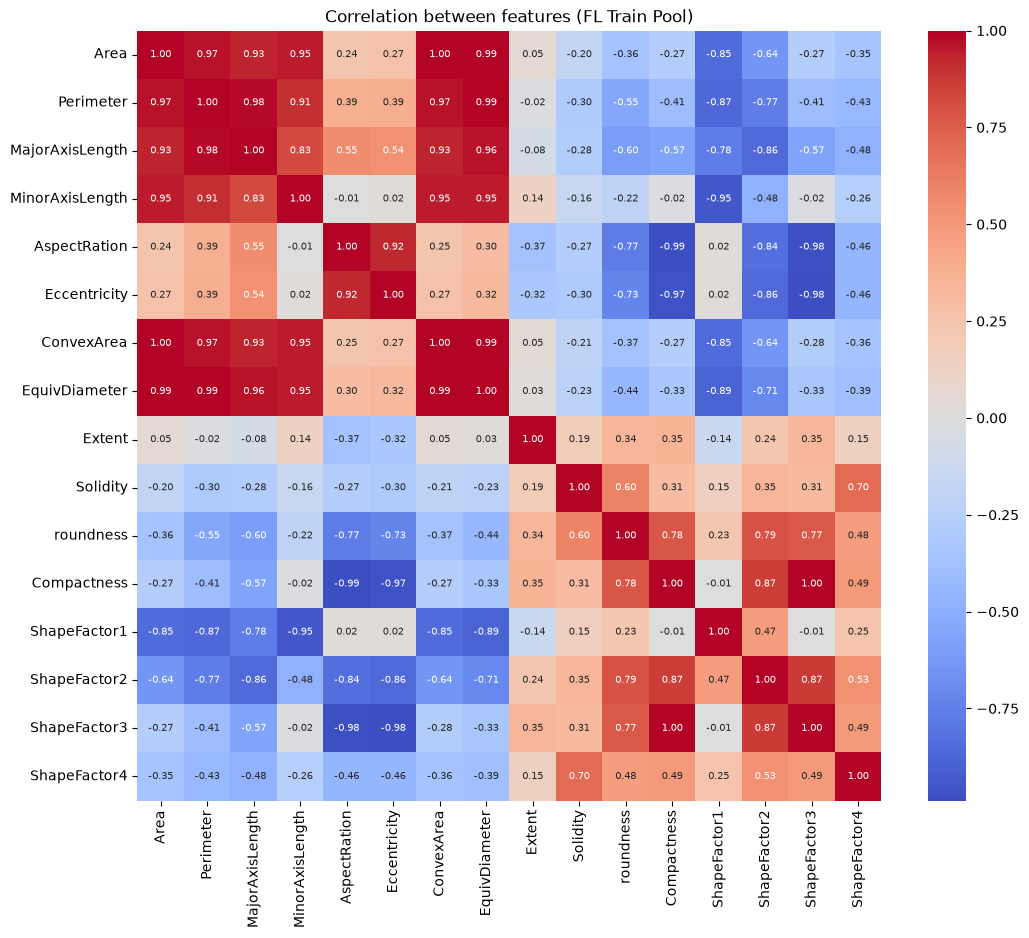

In [9]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_pool_raw.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation between features (FL Train Pool)')
plt.show()

**Висновок.** На тепловій карті видно дві великі групи майже однакових ознак:
- **розмір зерна**: `Area`, `ConvexArea` (r = 1.00 з `Area`), `EquivDiameter`, `Perimeter`, `MajorAxisLength`, `MinorAxisLength` - кореляції від 0.83 до 1.00. Логічно: усе це по-різному виміряний розмір;
- **видовженість**: `AspectRation`, `Eccentricity`, `Compactness`, `ShapeFactor3` - кореляції від 0.92 до 0.999 (`Compactness` і `ShapeFactor3` майже однакові, r ~ 0.999).

Але "сильно пов'язані" ще не означає "копія": дублікатом далі вважаємо лише пару з |r| > 0.95. Наприклад,
`MajorAxisLength` з `Area` має r ~ 0.93, а `Eccentricity` з `AspectRation` - r ~ 0.92, тому вони лишаться.

`Extent`, `Solidity`, `ShapeFactor4` майже ні з чим сильно не пов'язані - вони несуть окрему інформацію.
Така сильна мультиколінеарність робить ваги нестабільними (модель може "розподіляти" вагу між двома копіями як завгодно), тому з кожної групи варто лишити не всі ознаки.

Тепер зв'язок кожної ознаки з ціллю. Ціль тут - категорія (сорт), тому звичайна кореляція Пірсона не підходить.
Замість неї беремо **F-статистику ANOVA** (`f_classif`): вона порівнює, наскільки далеко один від одного середні значення ознаки в різних класах, з тим, наскільки ознака "розкидана" всередині класів.
Велике F - класи за цією ознакою добре розходяться.

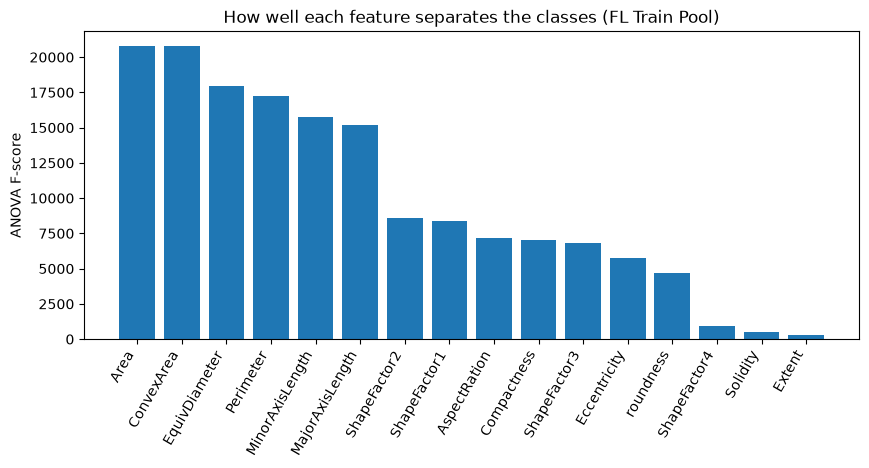

Area               20803.0
ConvexArea         20793.0
EquivDiameter      17922.0
Perimeter          17271.0
MinorAxisLength    15742.0
MajorAxisLength    15210.0
ShapeFactor2        8579.0
ShapeFactor1        8394.0
AspectRation        7158.0
Compactness         7018.0
ShapeFactor3        6837.0
Eccentricity        5724.0
roundness           4711.0
ShapeFactor4         908.0
Solidity             481.0
Extent               306.0
dtype: float64

In [10]:
f_values, _ = f_classif(X_pool_raw, y_pool_str)
f_scores = pd.Series(f_values, index=X_pool_raw.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 4))
plt.bar(f_scores.index, f_scores.values)
plt.xticks(rotation=60, ha='right')
plt.ylabel('ANOVA F-score')
plt.title('How well each feature separates the classes (FL Train Pool)')
plt.show()
f_scores.round(0)

**Висновок.** Найкраще класи розділяють ознаки розміру (`Area` F ~ 20 800, `ConvexArea`, `EquivDiameter`, `Perimeter`), потім ознаки форми (`ShapeFactor1/2`, `AspectRation`). Найслабші - `Extent` (F ~ 306) і `Solidity` (~ 481), але навіть вони не нульові, тобто трохи інформації мають. Важливо: F-статистика дивиться на кожну ознаку окремо, тому дві ознаки-копії отримують майже однакове високе F - саме тому F треба поєднати з кореляціями між ознаками.

**Правило відбору:** йдемо по ознаках від найбільшого F до найменшого і беремо ознаку, тільки якщо її кореляція
(за модулем) з кожною вже взятою ознакою не більша за 0.95. Так з кожної групи "дублікатів" лишається
найкорисніша ознака.

In [ ]:
corr = X_pool_raw.corr().abs()
features = []
for name in f_scores.index:
    duplicates = [kept for kept in features if corr.loc[name, kept] > 0.95]
    if duplicates:
        print(f'drop {name:16s} |r| > 0.95 with {duplicates}')
    else:
        features.append(name)

print()
print(len(features), 'features kept:', features)

drop ConvexArea       |r| > 0.95 with ['Area']
drop EquivDiameter    |r| > 0.95 with ['Area']
drop Perimeter        |r| > 0.95 with ['Area']
drop MinorAxisLength  |r| > 0.95 with ['Area']
drop Compactness      |r| > 0.95 with ['AspectRation']
drop ShapeFactor3     |r| > 0.95 with ['AspectRation']

10 features kept: ['Area', 'MajorAxisLength', 'ShapeFactor2', 'ShapeFactor1', 'AspectRation', 'Eccentricity', 'roundness', 'ShapeFactor4', 'Solidity', 'Extent']


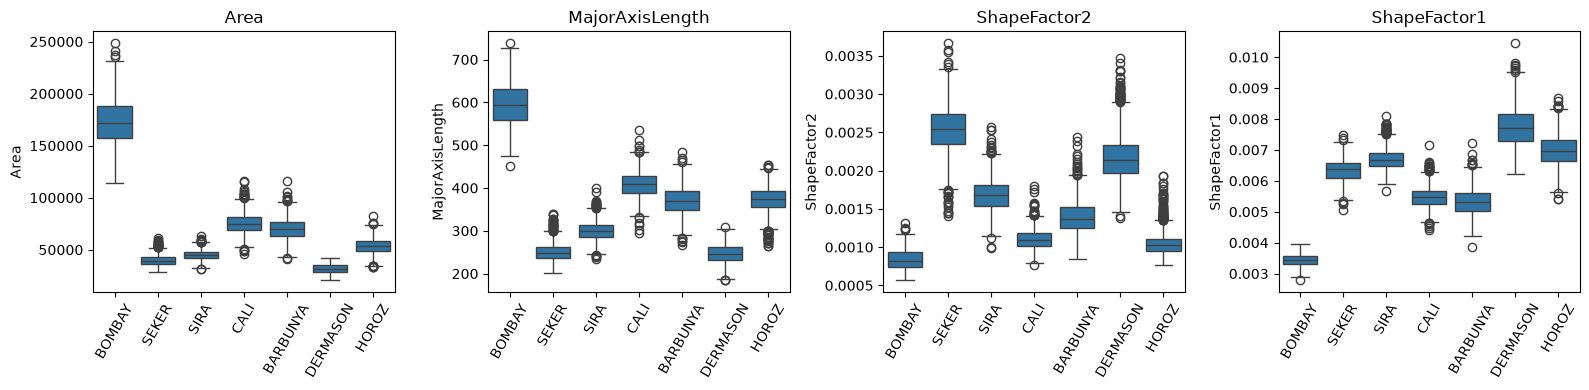

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, name in zip(axes, features[:4]):
    sns.boxplot(x=y_pool_str, y=X_pool_raw[name], ax=ax)
    ax.set_title(name)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

**Висновок.** Прибрано 6 ознак-дублікатів: `ConvexArea`, `EquivDiameter`, `Perimeter`, `MinorAxisLength` (копії `Area`) і `Compactness`, `ShapeFactor3` (копії `AspectRation`). Лишилось **10 ознак**. Ознаки зі слабким F (`Extent`, `Solidity`) ми не викидаємо: вони не дублюють інші, а модель сама дасть їм малі ваги, якщо вони непотрібні.

Boxplot-и показують, чому задача непогано розв'язується лінійною моделлю: `BOMBAY` відділяється від усіх одним лише розміром (`Area` ~175 тис. проти < 80 тис. в інших), `SEKER` має найбільший `ShapeFactor2`. А от `DERMASON` і `SIRA` дуже близькі за розміром (`Area` ~33 тис. і ~44 тис., "ящики" майже поряд) - очікуємо, що саме їх модель плутатиме найчастіше.

Ridge-регуляризація теж допомогла б з мультиколінеарністю, але прибрати копії простіше: ваги стають зрозумілішими, а модель - меншою (10x7 замість 16x7 ваг).

### 1.4 Кодування категоріальних ознак

У Dry Bean **немає категоріальних ознак** - усі 16 ознак числові, тож кодувати нічого не треба.

- **One-Hot Encoding** - кожна категорія стає окремою колонкою 0/1. Для номінальних категорій без порядку
  (район, колір). Мінус - багато колонок, якщо категорій багато.
- **Ordinal Encoding** - категорії замінюються числами 1, 2, 3... Тільки якщо є природний порядок
  (погано < нормально < добре), інакше модель "побачить" порядок, якого немає.
- **Target Encoding** - категорія замінюється середнім значенням цілі для неї. Зручно для дуже великої кількості категорій, але легко отримати витік даних, тому рахувати треба лише на train (бажано з крос-валідацією).

Кодуємо тільки **ціль**: назви сортів -> номери 0...6 (`LabelEncoder`, навчений на FL Train Pool),
а потім номери -> one-hot матриця $Y \in \{0,1\}^{m \times C}$, яку вимагає формула втрат.

In [13]:
encoder = LabelEncoder().fit(y_pool_str)
class_names = encoder.classes_
C = len(class_names)

y_pool = encoder.transform(y_pool_str)
y_val = encoder.transform(y_val_str)
y_test = encoder.transform(y_test_str)


def one_hot(y, C):
    return np.eye(C)[y]  # row y of the identity matrix = one-hot vector


Y_pool, Y_val, Y_test = one_hot(y_pool, C), one_hot(y_val, C), one_hot(y_test, C)
print('Classes:', list(class_names))
print('First 3 labels:', y_pool[:3])
print(Y_pool[:3])

Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
First 3 labels: [1 5 6]
[[0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 1.]]


### 1.5 Масштабування (стандартизація)

Ознаки мають дуже різні масштаби (площа ~ десятки тисяч, `ShapeFactor2` ~ тисячні), тому стандартизуємо:
$x' = (x - \mu) / \sigma$.

Використовуємо **спрощений підхід (а)** з завдання: $\mu$ і $\sigma$ рахуємо на всьому FL Train Pool **до** розподілу між клієнтами і вважаємо це частиною симуляції. Validation і Test тільки трансформуємо цими ж числами. В етапі 4 перевіримо, що "більш федеративний" підхід (б) - коли кожен клієнт надсилає лише свої середні та дисперсії - дає точно ті самі $\mu$ і $\sigma$, тобто спрощення нічого не змінює.

In [14]:
X_pool_raw_np = X_pool_raw[features].values

# scaling parameters are computed on FL Train Pool only
mu = X_pool_raw_np.mean(axis=0)
sigma = X_pool_raw_np.std(axis=0)


def scale(X_raw):
    return (X_raw[features].values - mu) / sigma


X_pool, X_val, X_test = scale(X_pool_raw), scale(X_val_raw), scale(X_test_raw)
d = X_pool.shape[1]

print('X_pool:', X_pool.shape, ' X_val:', X_val.shape, ' X_test:', X_test.shape)
print('Pool mean:', X_pool.mean(axis=0).round(3))
print('Pool std: ', X_pool.std(axis=0).round(3))
print('Val mean: ', X_val.mean(axis=0).round(3))

X_pool: (9479, 10)  X_val: (2032, 10)  X_test: (2032, 10)
Pool mean: [ 0.  0.  0.  0.  0. -0.  0.  0. -0. -0.]
Pool std:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Val mean:  [-0.005 -0.002 -0.005  0.012  0.011  0.009 -0.023 -0.019 -0.022  0.005]


На Pool середні рівно 0 і std рівно 1, а на Validation - близькі до 0, але не точно, бо $\mu$ і $\sigma$ "не бачили" цих даних.
Так і має бути: якби на Validation теж вийшло рівно 0, це означало б, що ми рахували параметри і на ній.

---

## 2. Етап 2. Багатокласова логістична регресія на numpy

У звичайній (бінарній) логістичній регресії лінійна частина $z = xw + b$ проходить через сигмоїду і дає одну ймовірність.
Для $C$ класів робимо $C$ лінійних частин одразу (по одній на клас) і замість сигмоїди беремо **softmax** -
він перетворює $C$ довільних чисел на $C$ ймовірностей, що в сумі дають 1.

- $X \in \mathbb{R}^{m \times d}$, $Y \in \{0,1\}^{m \times C}$, $W \in \mathbb{R}^{d \times C}$, $b \in \mathbb{R}^{1 \times C}$
- $Z = XW + b$, $\quad P = \text{softmax}(Z)$, $\quad P_{ic} = \dfrac{e^{Z_{ic}}}{\sum_{j=1}^{C} e^{Z_{ij}}}$
- втрати з Ridge: $J(W,b) = -\dfrac{1}{m}\sum_{i=1}^{m}\sum_{c=1}^{C} Y_{ic}\log P_{ic} + \dfrac{\lambda}{2}\|W\|_F^2$ - градієнти: $\dfrac{\partial J}{\partial W} = \dfrac{1}{m}X^\top(P - Y) + \lambda W$, $\quad \dfrac{\partial J}{\partial b} = \dfrac{1}{m}\mathbf{1}_m^\top(P - Y)$

**Числова стабільність.** $e^{1000}$ - це вже `inf`. Але softmax не змінюється, якщо від усіх $z$ у рядку відняти одне й те саме число: $\frac{e^{z_c - a}}{\sum_j e^{z_j - a}} = \frac{e^{z_c}}{\sum_j e^{z_j}}$. Віднімаємо максимум рядка - тоді найбільший показник дорівнює 0 і переповнення немає. А в $\log$ додаємо $10^{-12}$, щоб не отримати $\log 0$.

In [ ]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    exp_Z = np.exp(Z)
    return exp_Z / exp_Z.sum(axis=1, keepdims=True)


def predict_proba(X, W, b):
    return softmax(X @ W + b)


def predict(X, W, b):
    return predict_proba(X, W, b).argmax(axis=1)


def compute_loss(X, Y, W, b, lam):
    m = len(X)
    P = predict_proba(X, W, b)
    cross_entropy = -np.sum(Y * np.log(P + 1e-12)) / m
    return cross_entropy + lam / 2 * np.sum(W ** 2)  # b is not regularized


def compute_gradients(X, Y, W, b, lam):
    m = len(X)
    error = predict_proba(X, W, b) - Y  # P - Y, shape (m, C)
    dW = X.T @ error / m + lam * W
    db = error.mean(axis=0, keepdims=True)  # same as 1^T (P - Y) / m
    return dW, db


def update_params(W, b, dW, db, lr):
    W = W - lr * dW
    b = b - lr * db
    return W, b


def init_params(d, C):
    return np.zeros((d, C)), np.zeros((1, C))  # loss is convex, zeros are a fine start

**Перевірки:** (1) рядки softmax дають в сумі 1; (2) softmax не ламається на величезних числах;
(3) з нульовими вагами модель дає всім класам ймовірність $1/C$, тому втрати мають дорівнювати $\log C = \log 7 \approx 1.946$.

In [16]:
Z = np.random.randn(5, C)
print('Row sums:', softmax(Z).sum(axis=1))
assert np.allclose(softmax(Z).sum(axis=1), 1)

with np.errstate(over='ignore'):
    print('Naive exp(1000):', np.exp(1000.0))
assert np.allclose(softmax(Z + 1000), softmax(Z))
assert np.all(np.isfinite(softmax(Z + 1000)))

W0, b0 = init_params(d, C)
loss0 = compute_loss(X_pool, Y_pool, W0, b0, 0)
print('Loss with zero weights:', round(loss0, 4), ' log(C):', round(np.log(C), 4))
assert np.isclose(loss0, np.log(C))
print('OK')

Row sums: [1. 1. 1. 1. 1.]
Naive exp(1000): inf
Loss with zero weights: 1.9459  log(C): 1.9459
OK


**Перевірка градієнта.** Порівнюємо аналітичний градієнт з чисельною похідною
$\frac{J(\theta + \varepsilon) - J(\theta - \varepsilon)}{2\varepsilon}$ для випадкових елементів $W$ і для всіх елементів $b$
(з $\lambda = 0.1$, щоб перевірити і доданок регуляризації). Відносна похибка має бути дуже малою ($< 10^{-6}$).

In [17]:
rng = np.random.default_rng(SEED)
X_small, Y_small = X_pool[:200], Y_pool[:200]
W = rng.normal(0, 0.1, size=(d, C))
b = rng.normal(0, 0.1, size=(1, C))
lam, eps = 0.1, 1e-5
dW, db = compute_gradients(X_small, Y_small, W, b, lam)

# positions to check: 10 random entries of W and every entry of b
checks = [('W', rng.integers(d), rng.integers(C)) for _ in range(10)] + [('b', 0, j) for j in range(C)]
errors = []
for name, i, j in checks:
    W_plus, b_plus, W_minus, b_minus = W.copy(), b.copy(), W.copy(), b.copy()
    if name == 'W':
        W_plus[i, j] += eps
        W_minus[i, j] -= eps
        analytic = dW[i, j]
    else:
        b_plus[i, j] += eps
        b_minus[i, j] -= eps
        analytic = db[i, j]
    numeric = (compute_loss(X_small, Y_small, W_plus, b_plus, lam)
               - compute_loss(X_small, Y_small, W_minus, b_minus, lam)) / (2 * eps)
    errors.append(abs(numeric - analytic) / (abs(numeric) + abs(analytic)))

print('Max relative error:', f'{max(errors):.2e}')
assert max(errors) < 1e-6
print('OK')

Max relative error: 4.22e-10
OK


**Навчання міні-батчевим градієнтним спуском.** На кожній епосі перемішуємо приклади, ділимо на батчі, на кожному батчі робимо крок. Функція приймає **початкові** $W, b$ - це знадобиться в FL, де клієнт стартує не з нулів, а з глобальної моделі сервера.

В історію пишемо втрати на train (з регуляризацією - те, що реально мінімізуємо) і на validation (чистий log-loss без $\lambda$, бо саме за ним порівнюємо моделі з різними $\lambda$).

In [ ]:
def train_minibatch(X, Y, W, b, lr, epochs, batch_size, lam, seed, X_val=None, Y_val=None):
    history = {'train_loss': [], 'val_loss': []}
    m = len(X)
    if m == 0:
        return W, b, history

    rng = np.random.default_rng(seed)
    history['train_loss'].append(compute_loss(X, Y, W, b, lam))
    if X_val is not None:
        history['val_loss'].append(compute_loss(X_val, Y_val, W, b, 0))

    for epoch in range(epochs):
        indices = rng.permutation(m)  # shuffle before every epoch
        for start in range(0, m, batch_size):
            batch = indices[start:start + batch_size]
            dW, db = compute_gradients(X[batch], Y[batch], W, b, lam)
            W, b = update_params(W, b, dW, db, lr)

        history['train_loss'].append(compute_loss(X, Y, W, b, lam))
        if X_val is not None:
            history['val_loss'].append(compute_loss(X_val, Y_val, W, b, 0))

    return W, b, history

---
## 3. Етап 3. Централізована модель (базова лінія)

Навчаємо модель на всьому FL Train Pool, ніби всі дані лежать в одному місці. Це "стеля", з якою потім порівнюємо FL.
Гіперпараметри підбираємо по черзі на **Global Validation**: спочатку learning rate, потім розмір батчу, потім $\lambda$.
Критерій - найменший log-loss на validation. Global Test чіпаємо лише один раз, у кінці.

Метрики: accuracy, macro-F1 (середнє F1 по класах - кожен клас важить однаково), balanced accuracy (середній recall по класах), log-loss (наскільки впевнено і правильно модель дає ймовірності), confusion matrix.

In [ ]:
def evaluate(X, y, W, b):
    P = predict_proba(X, W, b)
    y_hat = P.argmax(axis=1)
    return {
        'accuracy': accuracy_score(y, y_hat),
        'macro_f1': f1_score(y, y_hat, average='macro'),
        'balanced_acc': balanced_accuracy_score(y, y_hat),
        'log_loss': log_loss(y, P, labels=np.arange(C)),
    }


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(C), normalize='true')
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(title)
    plt.show()

### 3.1 Підбір learning rate

In [20]:
EPOCHS = 100

lr_rows, lr_histories = [], {}
for lr in [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0]:
    W, b = init_params(d, C)
    W, b, history = train_minibatch(X_pool, Y_pool, W, b, lr, EPOCHS, 64, 0, SEED, X_val, Y_val)
    lr_histories[lr] = history
    lr_rows.append({'lr': lr,
                    'train loss': history['train_loss'][-1],
                    'val loss': history['val_loss'][-1],
                    'val macro-F1': evaluate(X_val, y_val, W, b)['macro_f1']})

lr_table = pd.DataFrame(lr_rows)
LR = lr_table.loc[lr_table['val loss'].idxmin(), 'lr']
print('Chosen LR =', LR)
lr_table.round(4)

Chosen LR = 1.0


,lr,train loss,val loss,val macro-F1
0,0.001,0.5573,0.5814,0.8806
1,0.010,0.2591,0.2934,0.9253
2,0.100,0.2074,0.2380,0.9302
3,0.500,0.2040,0.2312,0.9303
4,1.000,0.2051,0.2309,0.9312
5,2.000,0.2088,0.2321,0.9312
6,5.000,0.2277,0.2462,0.9239


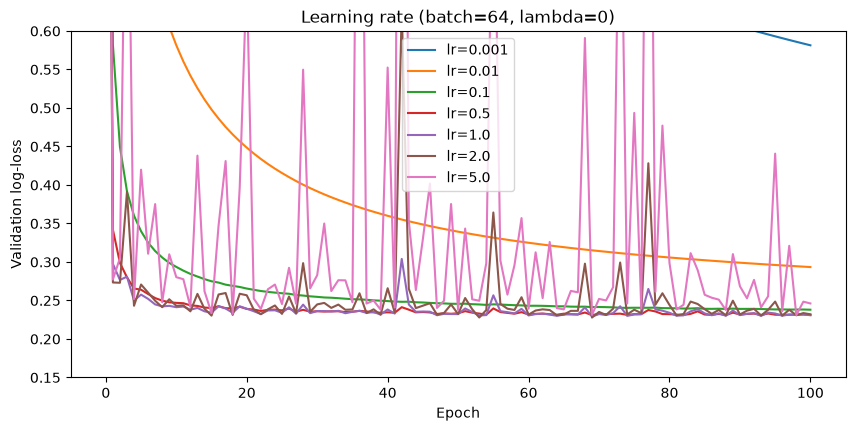

In [21]:
plt.figure(figsize=(10, 4.5))
for lr, history in lr_histories.items():
    plt.plot(history['val_loss'], label=f'lr={lr}')
plt.xlabel('Epoch')
plt.ylabel('Validation log-loss')
plt.ylim(0.15, 0.6)
plt.title('Learning rate (batch=64, lambda=0)')
plt.legend()
plt.show()

**Висновок.** Learning rate 0.001 надто малий: за 100 епох модель не встигла навчитися (val log-loss 0.58, macro-F1 0.88).
З 0.01 вже краще (0.29), але ще не зійшлося. Від 0.1 до 1.0 результат майже однаковий (val log-loss 0.231-0.238) - це "плато", модель дійшла до мінімуму. Найменші втрати при **lr = 1.0** (0.2309). При 2.0 і 5.0 втрати вже не зменшуються, а крива стає "зубчастою": кроки настільки великі, що модель перестрибує мінімум
(на графіку видно стрибки вгору). Тому обираємо `LR = 1.0` - найбільший крок, який ще стабільний.

Такий великий lr тут можливий, бо ознаки стандартизовані: після стандартизації "чаша" функції втрат приблизно однаково вигнута в усіх напрямках і не дуже крута, тому навіть великий крок не перестрибує мінімум. (Допустимий крок залежить саме від кривизни втрат, а вона в softmax-регресії не більша, ніж у $\frac{1}{2}X^\top X/m$, - після стандартизації це невелике число.)

### 3.2 Підбір розміру батчу

In [22]:
batch_rows, batch_histories = [], {}
for batch_size in [16, 64, 256, len(X_pool)]:
    W, b = init_params(d, C)
    start = time.perf_counter()
    W, b, history = train_minibatch(X_pool, Y_pool, W, b, LR, EPOCHS, batch_size, 0, SEED, X_val, Y_val)
    seconds = time.perf_counter() - start
    batch_histories[batch_size] = history
    batch_rows.append({'batch': batch_size,
                       'train loss': history['train_loss'][-1],
                       'val loss': history['val_loss'][-1],
                       'val macro-F1': evaluate(X_val, y_val, W, b)['macro_f1'],
                       'seconds': seconds})

batch_table = pd.DataFrame(batch_rows)
BATCH = int(batch_table.loc[batch_table['val loss'].idxmin(), 'batch'])
print('Chosen BATCH =', BATCH)
batch_table.round(4)

Chosen BATCH = 64


,batch,train loss,val loss,val macro-F1,seconds
0,16,0.2170,0.2373,0.9244,2.0844
1,64,0.2051,0.2309,0.9312,0.9009
2,256,0.2047,0.2326,0.9299,0.5220
3,9479,0.2828,0.3161,0.9227,0.3704


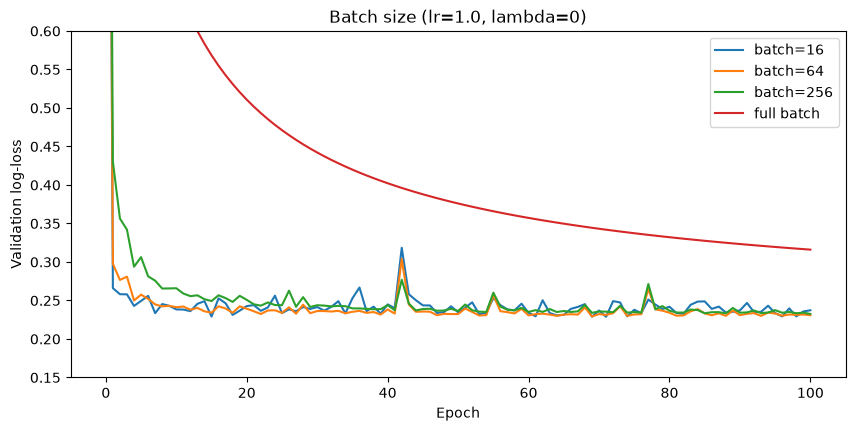

In [23]:
plt.figure(figsize=(10, 4.5))
for batch_size, history in batch_histories.items():
    label = 'full batch' if batch_size == len(X_pool) else f'batch={batch_size}'
    plt.plot(history['val_loss'], label=label)
plt.xlabel('Epoch')
plt.ylabel('Validation log-loss')
plt.ylim(0.15, 0.6)
plt.title(f'Batch size (lr={LR}, lambda=0)')
plt.legend()
plt.show()

**Висновок.**
- **batch = 16**: найгірший з міні-батчів (val loss 0.237) і найповільніший - з lr = 1.0 градієнт по 16 прикладах дуже шумний, кроки "смикають" ваги в різні боки.
- **batch = 64**: найкращий val loss (0.231).
- **batch = 256**: майже так само (0.233) і трохи швидше (точний час - у колонці `seconds`, він трохи змінюється від запуску до запуску).
- **повний батч** (Batch GD, 9 479 прикладів): найшвидший, але найгірший (0.316) - за 100 епох це лише 100 кроків, модель ще не дійшла до мінімуму.

Це той самий компроміс, що і в Лабораторній 1: малий батч - багато шумних кроків, великий - мало точних кроків.
Обираємо `BATCH = 64`.

### 3.3 Вплив Ridge-регуляризації

Ridge додає до втрат штраф $\frac{\lambda}{2}\|W\|_F^2$, тобто "тягне" ваги до нуля. Великі ваги означають, що модель
дуже різко реагує на малі зміни ознак, - це ознака перенавчання. Зміщення $b$ не штрафуємо.

In [24]:
lam_rows = []
for lam in [0, 1e-4, 1e-3, 1e-2, 1e-1, 1]:
    W, b = init_params(d, C)
    W, b, history = train_minibatch(X_pool, Y_pool, W, b, LR, EPOCHS, BATCH, lam, SEED, X_val, Y_val)
    lam_rows.append({'lambda': lam,
                     'train loss': history['train_loss'][-1],
                     'val loss': history['val_loss'][-1],
                     'val macro-F1': evaluate(X_val, y_val, W, b)['macro_f1'],
                     '||W||': np.linalg.norm(W)})

lam_table = pd.DataFrame(lam_rows)
LAM = lam_table.loc[lam_table['val loss'].idxmin(), 'lambda']
print('Chosen LAM =', LAM)
lam_table.round(4)

Chosen LAM = 0.0


,lambda,train loss,val loss,val macro-F1,||W||
0,0.0000,0.2051,0.2309,0.9312,18.5843
1,0.0001,0.2195,0.2349,0.9304,15.2475
2,0.0010,0.2844,0.2613,0.9282,10.2665
3,0.0100,0.5155,0.3897,0.9164,5.5212
4,0.1000,1.1215,0.8635,0.7013,2.3414
5,1.0000,3.1685,2.0991,0.1248,1.4621


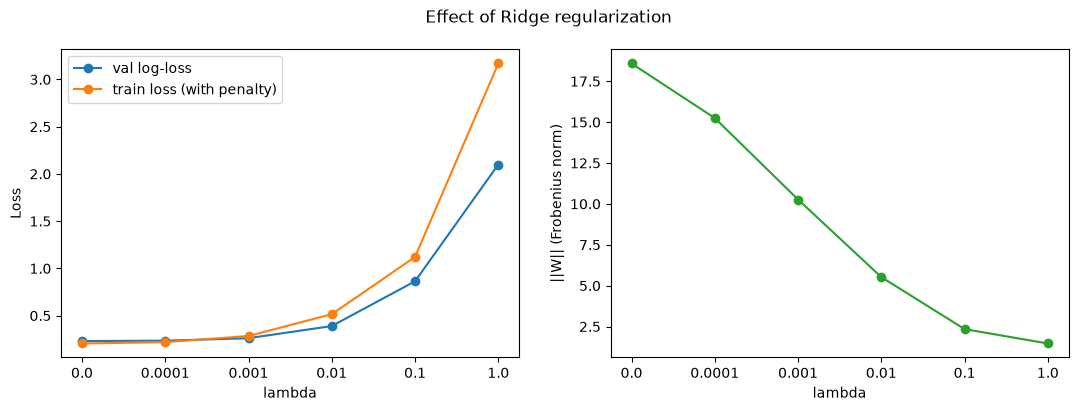

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = range(len(lam_table))
labels = [str(lam) for lam in lam_table['lambda']]
axes[0].plot(x, lam_table['val loss'], marker='o', label='val log-loss')
axes[0].plot(x, lam_table['train loss'], marker='o', label='train loss (with penalty)')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[1].plot(x, lam_table['||W||'], marker='o', color='tab:green')
axes[1].set_ylabel('||W|| (Frobenius norm)')
for ax in axes:
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels)
    ax.set_xlabel('lambda')
plt.suptitle('Effect of Ridge regularization')
plt.show()

**Висновок.** Що більше $\lambda$, то менша норма ваг: від 18.6 при $\lambda = 0$ до 1.5 при $\lambda = 1$ - Ridge справді "стискає" ваги. Але якість на validation від цього тільки **гіршає**: log-loss 0.231 -> 0.235 -> 0.261 -> 0.390, а при $\lambda = 0.1$ і $1$ модель уже сильно недонавчена (macro-F1 0.70 і 0.12 - майже завжди передбачає один клас).

Регуляризація допомагає, коли модель перенавчається. Тут цього немає: у нас 9 479 прикладів і лише 10x7 + 7 = 77 параметрів, а різниця між train і val втратами мала (0.205 проти 0.231). Тому штраф лише додає зміщення (bias).
Обираємо `LAM = 0`. (Train loss на графіку росте з $\lambda$, бо він включає сам штраф $\frac{\lambda}{2}\|W\|^2$.)

**Застереження щодо $\lambda = 0.1$ і $\lambda = 1$.** Крок оновлення з Ridge: $W \leftarrow (1 - \text{lr}\cdot\lambda)\,W - \text{lr}\cdot\nabla_{CE}$.
При lr = 1 і $\lambda = 1$ множник $(1 - \text{lr}\cdot\lambda) = 0$, тобто на кожному кроці ваги повністю "стираються" і замінюються градієнтом одного батчу - навчання стрибає (val log-loss 2.10 - гірше, ніж просто завжди передбачати частоти класів, ~ 1.83).
Тобто для великих $\lambda$ цей lr завеликий, і цифри 0.70 та 0.12 перебільшують шкоду саме від регуляризації
(з меншим lr вони були б кращими). Але й тоді великі $\lambda$ гірші за $\lambda = 0$, тому вибір `LAM = 0` не змінюється.

### 3.4 Фінальна централізована модель

Навчаємо модель з обраними гіперпараметрами, дивимося на криві навчання, і лише тепер - оцінка на Global Test.

EPOCHS=100, LR=1.0, BATCH=64, LAM=0.0


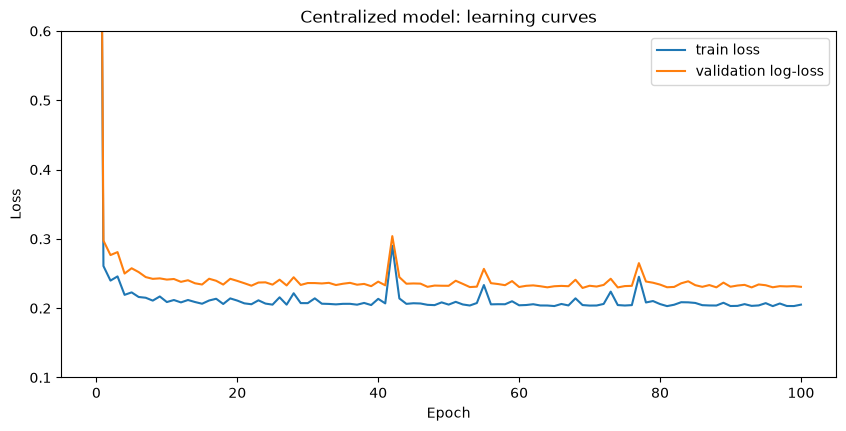

In [26]:
print(f'EPOCHS={EPOCHS}, LR={LR}, BATCH={BATCH}, LAM={LAM}')
W, b = init_params(d, C)
W_central, b_central, central_history = train_minibatch(
    X_pool, Y_pool, W, b, LR, EPOCHS, BATCH, LAM, SEED, X_val, Y_val)

plt.figure(figsize=(10, 4.5))
plt.plot(central_history['train_loss'], label='train loss')
plt.plot(central_history['val_loss'], label='validation log-loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim(0.1, 0.6)
plt.title('Centralized model: learning curves')
plt.legend()
plt.show()

**Висновок.** Обидві криві різко падають за перші ~10 епох, далі майже не змінюються - модель зійшлася.
Validation loss трохи вищий за train (~ 0.23 проти ~ 0.21), але цей розрив маленький і **не росте** з епохами,
тобто перенавчання немає. Невеликі "зубці" - це шум міні-батчевого спуску з великим lr.

In [27]:
central_val = evaluate(X_val, y_val, W_central, b_central)
central_test = evaluate(X_test, y_test, W_central, b_central)
pd.DataFrame({'Global Validation': central_val, 'Global Test': central_test}).round(4)

,Global Validation,Global Test
accuracy,0.9222,0.9144
macro_f1,0.9312,0.9275
balanced_acc,0.9306,0.9277
log_loss,0.2350,0.2323


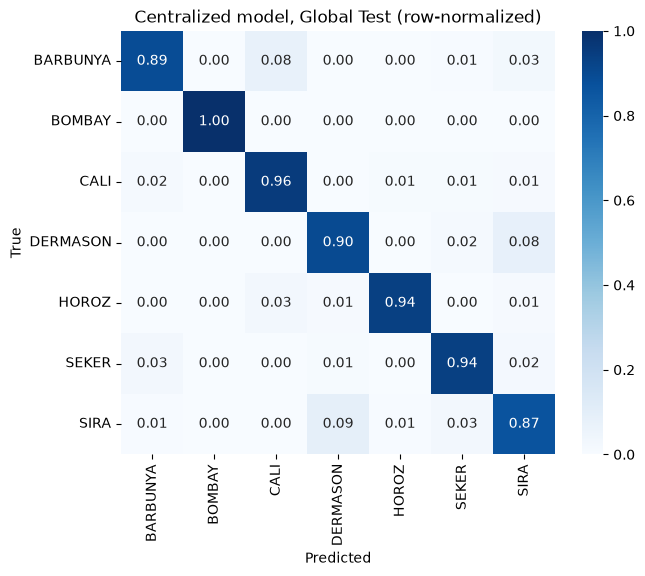

In [28]:
plot_confusion(y_test, predict(X_test, W_central, b_central), 'Centralized model, Global Test (row-normalized)')

**Висновок.** На Global Test централізована модель має accuracy **0.914**, macro-F1 **0.928**, balanced accuracy **0.928**, log-loss **0.232**. Результати на validation і test майже однакові - ми не "підігнали" гіперпараметри під validation.

Матриця помилок підтверджує очікування з EDA:
- `BOMBAY` - 100% (він набагато більший за всіх);
- найчастіше плутаються **`DERMASON` <-> `SIRA`** (8% `DERMASON` модель називає `SIRA`, 9% `SIRA` - `DERMASON`)
  і **`BARBUNYA` -> `CALI`** (8%) - це сорти, близькі за розміром і формою;
- найгірший recall у `SIRA` (0.87) і `BARBUNYA` (0.89).

Accuracy (0.914) трохи нижча за macro-F1 (0.928), бо найважчі класи `DERMASON` і `SIRA` - ще й найбільші (разом ~46% даних): accuracy рахує кожне зерно, тож їхні помилки важать більше, а macro-F1 дає кожному класу однакову вагу.

---
## 4. Етап 4. Розподіл даних між клієнтами та сервером

### 4.1 Архітектура: хто що бачить

| | Global Test | Global Validation | Свої дані $D_k$ | Дані інших клієнтів | Ваги інших клієнтів |
|---|---|---|---|---|---|
| **Сервер** | так | так | ні | ні | так (лише для агрегації) |
| **Клієнт k** | ні | ні | так | ні | ні (бачить лише агреговану глобальну модель) |

**Як це забезпечено в коді:** функція клієнта (`client_update`) отримує тільки глобальні $W, b$ і словник зі своїми
даними. Агрегація сервера (`fedavg`) отримує від клієнтів тільки $(W_k, b_k, n_k)$. `run_fedavg` - це цикл симуляції, який
грає обидві ролі (тому має доступ до списку клієнтів), але дані кожного клієнта передає лише в `client_update`
цього клієнта, а для оцінки глобальної моделі використовує лише `X_val` / `X_test`. Global Validation і Global Test клієнтам не передаються ніде.

### 4.2 Способи розподілу FL Train Pool між K клієнтами

- **IID** - перемішуємо всі індекси і ділимо на $K$ майже рівних частин. Кожен клієнт отримує приблизно однакову кількість
  прикладів і майже глобальні пропорції класів.
- **Non-IID (Діріхле)** - для кожного класу $c$ генеруємо частки $(p_{1c}, \dots, p_{Kc}) \sim \text{Dirichlet}(\alpha, \dots, \alpha)$
  (це $K$ невід'ємних чисел із сумою 1) і ділимо приклади класу $c$ між клієнтами в цих пропорціях.
  Мале $\alpha$ -> частки дуже нерівні (один клієнт забирає майже весь клас), велике $\alpha$ -> частки майже рівні (~ IID).

В обох випадках кожен приклад потрапляє рівно до одного клієнта, а зерно фіксоване (`SEED`), тому розподіл відтворюваний.
Основна кількість клієнтів: $K = 5$.

In [29]:
K = 5


def split_iid(y, K, seed):
    rng = np.random.default_rng(seed)
    return np.array_split(rng.permutation(len(y)), K)


def split_dirichlet(y, K, alpha, seed):
    rng = np.random.default_rng(seed)
    client_indices = [[] for _ in range(K)]
    for c in np.unique(y):
        idx_c = rng.permutation(np.where(y == c)[0])
        p = rng.dirichlet([alpha] * K)  # share of class c for every client
        cut_points = (np.cumsum(p) * len(idx_c)).astype(int)[:-1]
        for k, part in enumerate(np.split(idx_c, cut_points)):
            client_indices[k].extend(part)
    return [np.array(idx, dtype=int) for idx in client_indices]


def make_split(alpha, K=K):
    # alpha='IID' -> plain random split, otherwise Dirichlet with this alpha
    if alpha == 'IID':
        return split_iid(y_pool, K, SEED)
    return split_dirichlet(y_pool, K, alpha, SEED)


def make_clients(indices_list):
    return [{'X': X_pool[idx], 'Y': Y_pool[idx], 'y': y_pool[idx]} for idx in indices_list]


def describe_split(indices_list, y):
    rows = [np.bincount(y[idx], minlength=C) for idx in indices_list]
    table = pd.DataFrame(rows, columns=class_names, index=[f'client {k + 1}' for k in range(len(indices_list))])
    table['total'] = table.sum(axis=1)
    return table

In [30]:
splits = {alpha: make_split(alpha) for alpha in ['IID', 5, 1, 0.3]}

for name, indices_list in splits.items():
    # every pool example belongs to exactly one client
    assert np.array_equal(np.sort(np.concatenate(indices_list)), np.arange(len(y_pool)))
    sizes = [len(idx) for idx in indices_list]
    small = [k + 1 for k, n in enumerate(sizes) if n < 10]
    print(f'{str(name):>4}: sizes {sizes}, clients with < 10 examples: {small}')

# same seed -> exactly the same split
again = make_split(0.3)
assert all(np.array_equal(a, b) for a, b in zip(again, splits[0.3]))
print('OK: every example in exactly one client, split is reproducible')

 IID: sizes [1896, 1896, 1896, 1896, 1895], clients with < 10 examples: []
   5: sizes [1882, 1896, 1590, 2097, 2014], clients with < 10 examples: []
   1: sizes [1815, 1272, 2656, 2496, 1240], clients with < 10 examples: []
 0.3: sizes [1505, 1536, 1316, 1046, 4076], clients with < 10 examples: []
OK: every example in exactly one client, split is reproducible


In [31]:
for name, indices_list in splits.items():
    print(f'Split: {name}')
    display(describe_split(indices_list, y_pool))

Split: IID


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,total
client 1,167,69,233,510,261,302,354,1896
client 2,184,72,235,483,272,284,366,1896
client 3,193,70,217,507,273,264,372,1896
client 4,196,72,230,487,247,271,393,1896
client 5,186,83,225,495,249,298,359,1895


Split: 5


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,total
client 1,163,65,229,836,172,163,254,1882
client 2,228,32,166,518,233,379,340,1896
client 3,249,61,55,251,512,315,147,1590
client 4,166,82,454,205,171,232,787,2097
client 5,120,126,236,672,214,330,316,2014


Split: 1


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,total
client 1,317,34,52,992,196,168,56,1815
client 2,3,9,62,989,105,72,32,1272
client 3,297,71,1,176,564,253,1294,2656
client 4,281,127,764,136,368,710,110,2496
client 5,28,125,261,189,69,216,352,1240


Split: 0.3


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,total
client 1,83,132,0,206,960,124,0,1505
client 2,0,25,205,38,0,1096,172,1536
client 3,813,2,245,57,29,138,32,1316
client 4,7,138,54,0,5,0,842,1046
client 5,23,69,636,2181,308,61,798,4076


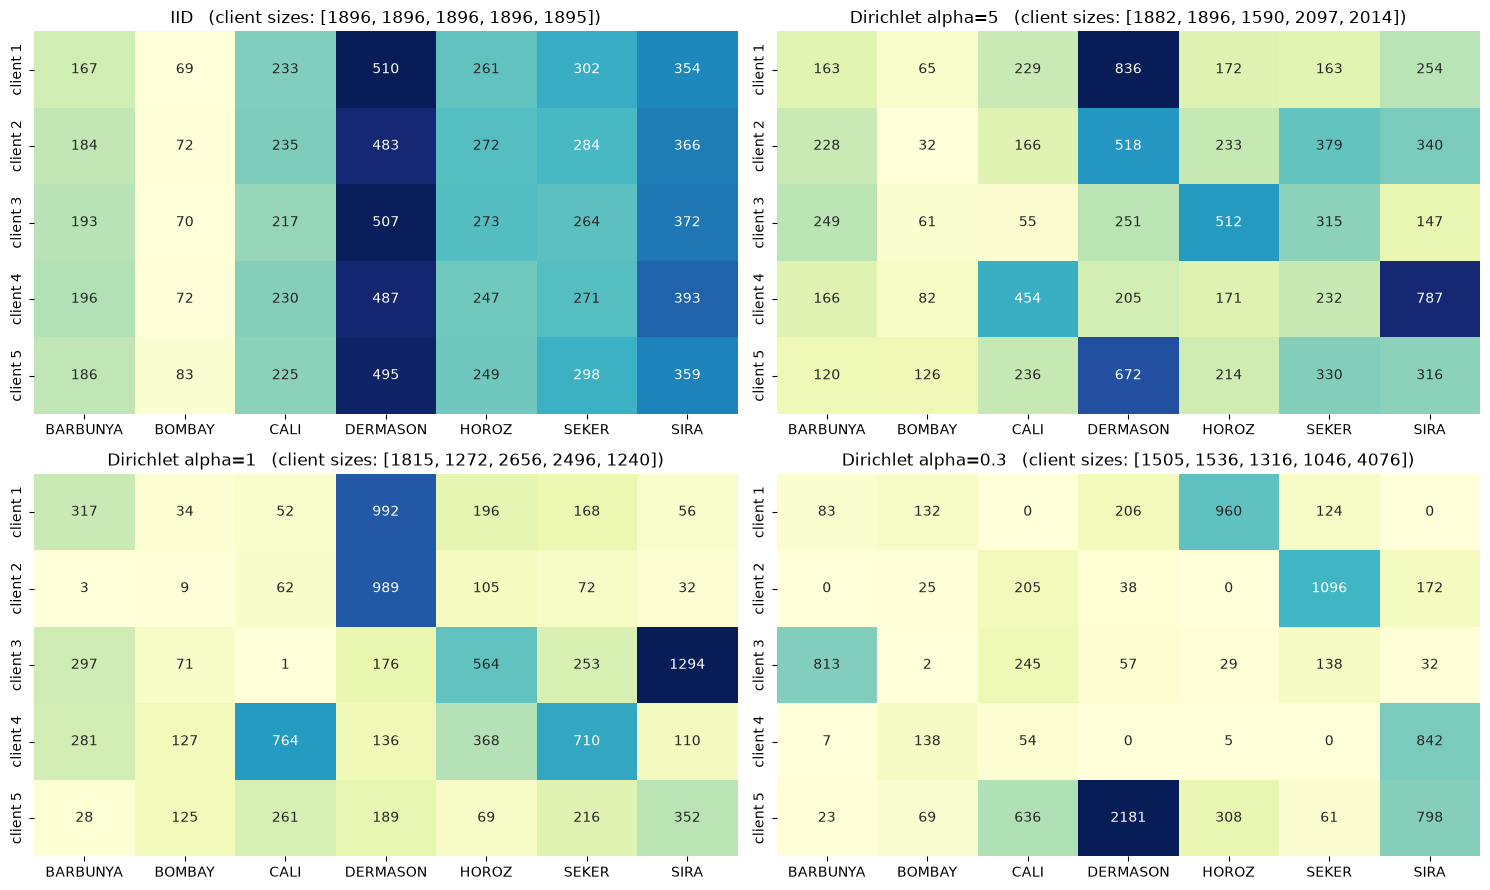

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (name, indices_list) in zip(axes.ravel(), splits.items()):
    table = describe_split(indices_list, y_pool)
    sns.heatmap(table[class_names], annot=True, fmt='d', cmap='YlGnBu', ax=ax, cbar=False)
    title = 'IID' if name == 'IID' else f'Dirichlet alpha={name}'
    ax.set_title(f'{title}   (client sizes: {list(table["total"])})')
plt.tight_layout()
plt.show()

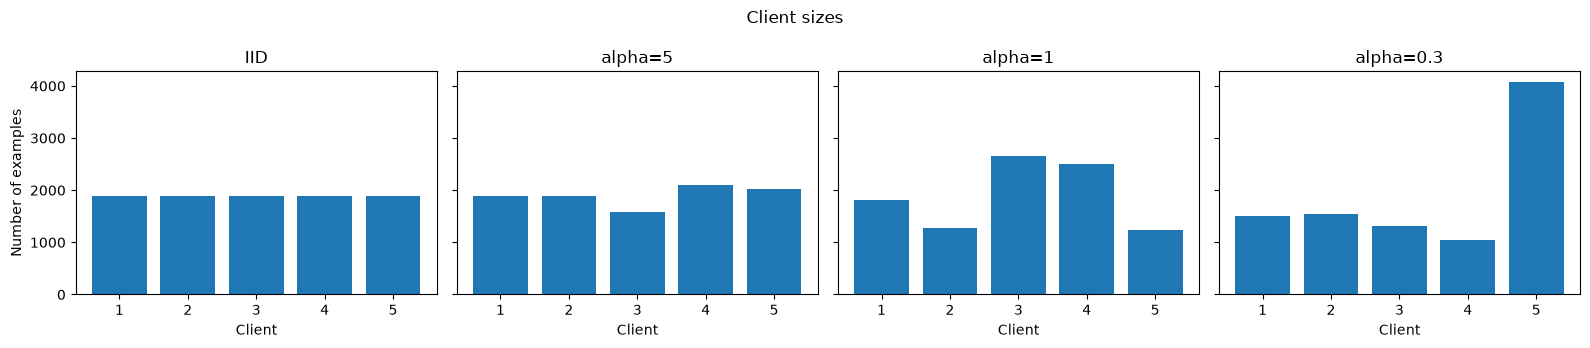

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (name, indices_list) in zip(axes, splits.items()):
    ax.bar([f'{k + 1}' for k in range(K)], [len(idx) for idx in indices_list])
    ax.set_title('IID' if name == 'IID' else f'alpha={name}')
    ax.set_xlabel('Client')
axes[0].set_ylabel('Number of examples')
plt.suptitle('Client sizes')
plt.tight_layout()
plt.show()

**Висновок.**
- **IID**: усі клієнти мають по 1 895-1 896 прикладів, а частки класів у кожного майже як у всьому пулі
  (наприклад, `DERMASON` 483-510 у кожного).
- **$\alpha$ = 5**: розміри вже трохи різні (1 590-2 097), класи розподілені нерівно, але кожен клієнт має всі сорти
  (найменше - 32 `BOMBAY` у клієнта 2, 55 `CALI` у клієнта 3).
- **$\alpha$ = 1**: помірна неоднорідність. Клієнт 2 має лише 3 `BARBUNYA` і 9 `BOMBAY`, клієнт 3 - лише **1** `CALI`.
- **$\alpha$ = 0.3**: сильна неоднорідність. Клієнт 5 має 4 076 прикладів (43% пулу), з них 2 181 `DERMASON`;
  у клієнта 1 немає `CALI` і `SIRA`, у клієнта 2 - `BARBUNYA` і `HOROZ`, у клієнта 4 - `DERMASON` і `SEKER`
  (зате майже весь його набір - `SIRA`).

Клієнтів з менш ніж 10 прикладами немає (найменший - 1 046 при $\alpha$ = 0.3), тобто кожен клієнт може щось навчити.

**Як це впливає на глобальну модель.** Клієнт, який не бачив класу, вчить свою модель ніколи його не передбачати,
а його градієнти тягнуть ваги до "свого" набору класів. Різні клієнти тягнуть у різні боки, і середнє їхніх моделей -
це компроміс, який гірше підходить для повного розподілу, ніж модель, навчена на всіх даних разом.
Перевіримо це в експерименті 1.

### 4.3 Федеративне масштабування (підхід б)

Перевіримо, що $\mu$ і $\sigma$ можна отримати, не передаючи серверу жодного сирого рядка.
Кожен клієнт надсилає лише $n_k$, свої середні $\bar{x}_k$ і дисперсії $s_k^2$ (по кожній ознаці). Сервер рахує:

$$\mu = \frac{\sum_k n_k \bar{x}_k}{N}, \qquad \sigma^2 = \frac{\sum_k n_k (s_k^2 + \bar{x}_k^2)}{N} - \mu^2$$

Друга формула - це $\text{Var}(x) = E[x^2] - (E[x])^2$, де $E[x^2]$ кожного клієнта дорівнює $s_k^2 + \bar{x}_k^2$.

In [34]:
for name in ['IID', 0.3]:
    client_stats = []
    for idx in splits[name]:
        X_k = X_pool_raw_np[idx]
        client_stats.append((len(X_k), X_k.mean(axis=0), X_k.var(axis=0)))  # only these numbers leave the client

    N = sum(n for n, _, _ in client_stats)
    mu_fed = sum(n * mean for n, mean, _ in client_stats) / N
    var_fed = sum(n * (var + mean ** 2) for n, mean, var in client_stats) / N - mu_fed ** 2

    assert np.allclose(mu_fed, mu) and np.allclose(np.sqrt(var_fed), sigma)
    print(f'{name}: federated mu/sigma == pooled mu/sigma, '
          f'max |diff| in sigma = {np.abs(np.sqrt(var_fed) - sigma).max():.1e}')

IID: federated mu/sigma == pooled mu/sigma, max |diff| in sigma = 1.1e-13
0.3: federated mu/sigma == pooled mu/sigma, max |diff| in sigma = 7.3e-12


**Висновок.** Для будь-якого розподілу (і IID, і сильно неоднорідного $\alpha$ = 0.3) агреговані статистики збігаються
з порахованими на всьому FL Train Pool до похибки округлення. Отже, підхід (а), який ми використали, дає
**ті самі числа**, що й "чесний" федеративний підхід (б), а сервер при цьому не побачив жодного сирого прикладу.

---
## 5. Етап 5. Симуляція федеративного навчання (FedAvg)

Алгоритм FedAvg:
1. Сервер ініціалізує глобальну модель $w^0$ (нулі).
2. На кожному раунді $t$ сервер обирає клієнтів $S_t$ - у нас **усі клієнти на кожному раунді**.
3. Сервер надсилає $w^t$ клієнтам.
4. Кожен клієнт $k$ вчиться $E$ локальних епох на своїх даних, починаючи з $w^t$ (наша `train_minibatch`).
5. Клієнт повертає $w_k^{t+1}$ і кількість своїх прикладів $n_k$.
6. Сервер усереднює: $w^{t+1} = \sum_{k \in S_t} \frac{n_k}{\sum_{j \in S_t} n_j} w_k^{t+1}$ (і для $W$, і для $b$).
7. Сервер оцінює нову глобальну модель на Global Validation.

Гіперпараметри локального навчання (`LR`, `BATCH`, `LAM`) беремо з централізованої моделі.
Кількість раундів `ROUNDS = 50`.

Крім якості, на кожному раунді міряємо **клієнтський дрейф (client drift)**: середню відстань
$\|W_k - W^{t+1}\|_F$ між моделями клієнтів після локального навчання і новою глобальною моделлю.
Що більша ця відстань, то сильніше клієнти "розбіглися" в різні боки.

In [35]:
ROUNDS = 50
E_MAIN = 5
ALPHA_MAIN = 1


def client_update(W, b, client, E, seed):
    # the client gets only the global weights and its own data
    W_k, b_k, _ = train_minibatch(client['X'], client['Y'], W, b, LR, E, BATCH, LAM, seed)
    return W_k, b_k, len(client['X'])


def fedavg(results, weighted=True):
    n = np.array([n_k for _, _, n_k in results], dtype=float)
    if weighted:
        weights = n / n.sum()  # bigger clients have more say
    else:
        weights = np.ones(len(results)) / len(results)
    W = sum(weight * W_k for weight, (W_k, _, _) in zip(weights, results))
    b = sum(weight * b_k for weight, (_, b_k, _) in zip(weights, results))
    return W, b


def run_fedavg(clients, rounds, E, weighted=True, seed=SEED):
    W, b = init_params(d, C)  # server initializes the global model
    history = {'val_loss': [], 'val_macro_f1': [], 'drift': []}
    for t in range(rounds):
        results = []
        for k, client in enumerate(clients):
            results.append(client_update(W, b, client, E, seed + 1000 * t + k))
        W, b = fedavg(results, weighted)

        # the server sees only weights and its own validation set
        history['drift'].append(np.mean([np.linalg.norm(W_k - W) for W_k, _, _ in results]))
        history['val_loss'].append(compute_loss(X_val, Y_val, W, b, 0))
        history['val_macro_f1'].append(evaluate(X_val, y_val, W, b)['macro_f1'])
    return W, b, history

**Перевірка агрегації** на простих прикладах, де відповідь відома наперед:

In [36]:
W1, b1 = np.ones((d, C)), np.ones((1, C))
W2, b2 = 3 * np.ones((d, C)), 3 * np.ones((1, C))

# identical models -> the same model
W_avg, b_avg = fedavg([(W1, b1, 10), (W1, b1, 50)])
assert np.allclose(W_avg, W1) and np.allclose(b_avg, b1)

# weighted: 1/4 * 1 + 3/4 * 3 = 2.5
W_avg, b_avg = fedavg([(W1, b1, 1), (W2, b2, 3)])
assert np.allclose(W_avg, 2.5) and np.allclose(b_avg, 2.5)

# unweighted: 1/2 * 1 + 1/2 * 3 = 2
W_avg, b_avg = fedavg([(W1, b1, 1), (W2, b2, 3)], weighted=False)
assert np.allclose(W_avg, 2.0) and np.allclose(b_avg, 2.0)
print('OK')

OK


**Питання: чому ваги клієнтів зважують за кількістю прикладів? Що буде при простому середньому?**

Централізована модель мінімізує середні втрати по **всіх прикладах**: $\frac{1}{N}\sum_i \ell_i = \sum_k \frac{n_k}{N} \cdot (\text{середні втрати клієнта } k)$.
Тобто кожен клієнт "важить" пропорційно до своїх даних. FedAvg зі зважуванням за $n_k$ відтворює саме цю ціль:
модель клієнта, навченого на 3000 прикладах, - набагато надійніша оцінка, ніж модель клієнта зі 100 прикладами.
При простому середньому кожен клієнт важить $1/K$ незалежно від розміру, тому маленькі клієнти (з шумною моделлю і часто лише кількома класами) отримують непропорційно великий вплив, і глобальна модель зсувається в бік їхніх даних. В IID з однаковими клієнтами різниці майже немає, а в Non-IID з дуже різними розмірами - є.
Перевірено числами в експерименті 1.

### 5.1 Основний запуск: Dirichlet $\alpha$ = 1, K = 5, E = 5

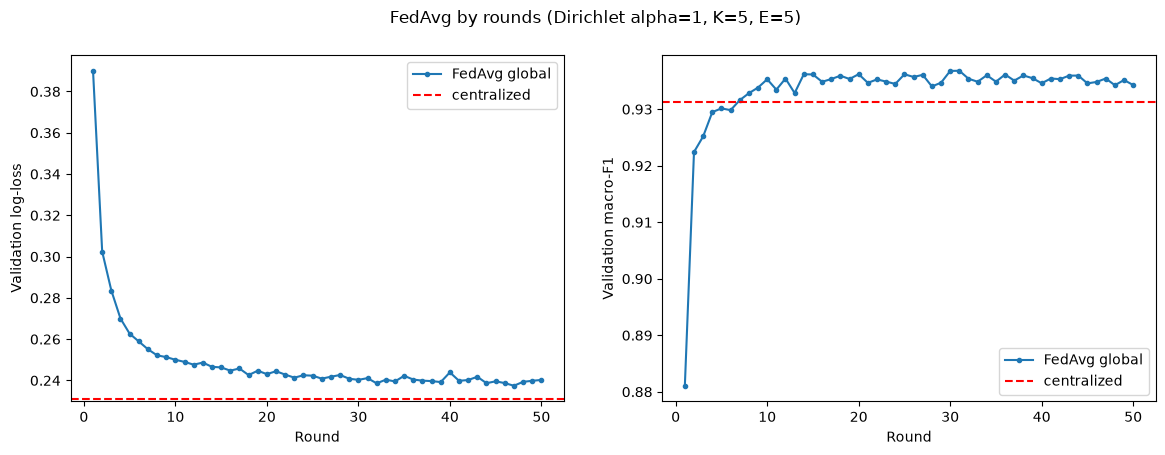

After round 1: val macro-F1 = 0.8811
After round 50: val macro-F1 = 0.9343  val log-loss = 0.2402


In [37]:
clients_main = make_clients(make_split(ALPHA_MAIN))
W_fed, b_fed, fed_history = run_fedavg(clients_main, ROUNDS, E_MAIN)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rounds_axis = range(1, ROUNDS + 1)
axes[0].plot(rounds_axis, fed_history['val_loss'], marker='.', label='FedAvg global')
axes[0].axhline(central_history['val_loss'][-1], color='red', linestyle='--', label='centralized')
axes[0].set_ylabel('Validation log-loss')
axes[1].plot(rounds_axis, fed_history['val_macro_f1'], marker='.', label='FedAvg global')
axes[1].axhline(central_val['macro_f1'], color='red', linestyle='--', label='centralized')
axes[1].set_ylabel('Validation macro-F1')
for ax in axes:
    ax.set_xlabel('Round')
    ax.legend()
plt.suptitle(f'FedAvg by rounds (Dirichlet alpha={ALPHA_MAIN}, K={K}, E={E_MAIN})')
plt.show()
print('After round 1: val macro-F1 =', round(fed_history['val_macro_f1'][0], 4))
print('After round 50: val macro-F1 =', round(fed_history['val_macro_f1'][-1], 4),
      ' val log-loss =', round(fed_history['val_loss'][-1], 4))

**Висновок.** Вже після першого раунду глобальна модель має macro-F1 на validation 0.881, а основне покращення відбувається
за перші ~10 раундів (log-loss падає з ~0.39 до ~0.25). Після 50 раундів: macro-F1 **0.934** (на рівні централізованої
моделі - 0.931), але log-loss **0.240** - гірше, ніж у централізованої (0.231; обидва числа пораховані нашою `compute_loss`). Тобто FedAvg майже досяг якості
централізованого навчання, хоча сервер жодного разу не бачив даних клієнтів. Log-loss тут чутливіший за F1: він
показує, що ймовірності глобальної моделі трохи менш точні.

---
## 6. Етап 6. Дослідження ефектів федеративного навчання

### 6.1 Порівняння локальних, глобальної та централізованої моделей (Global Test)

- **Локальна модель клієнта k** - навчена тільки на $D_k$ (з нуля, `EPOCHS` епох, ті самі гіперпараметри), без жодного обміну.
- **Глобальна FedAvg** - модель з розділу 5.1.
- **Централізована** - модель з розділу 3.4 (усі дані в одному місці).

Розподіл - той самий $\alpha$ = 1 (див. теплову карту в 4.2).

In [38]:
def train_local_models(clients):
    models = []
    for k, client in enumerate(clients):
        W, b = init_params(d, C)
        W, b, _ = train_minibatch(client['X'], client['Y'], W, b, LR, EPOCHS, BATCH, LAM, SEED + k)
        models.append((W, b))
    return models


local_models = train_local_models(clients_main)

rows = []
for k, (W, b) in enumerate(local_models):
    rows.append({'model': f'Local client {k + 1}', 'n_k': len(clients_main[k]['X']),
                 **evaluate(X_test, y_test, W, b)})
rows.append({'model': 'FedAvg global', 'n_k': len(X_pool), **evaluate(X_test, y_test, W_fed, b_fed)})
rows.append({'model': 'Centralized', 'n_k': len(X_pool), **central_test})
comparison = pd.DataFrame(rows).set_index('model')
comparison.round(4)

,n_k,accuracy,macro_f1,balanced_acc,log_loss
model,,,,,
Local client 1,1815,0.8711,0.8863,0.8901,0.3654
Local client 2,1272,0.8406,0.8414,0.8405,0.4825
Local client 3,2656,0.7894,0.7334,0.7960,1.0293
Local client 4,2496,0.8888,0.9054,0.9131,0.3076
Local client 5,1240,0.8962,0.9065,0.9049,0.3069
FedAvg global,9479,0.9124,0.9250,0.9271,0.2362
Centralized,9479,0.9144,0.9275,0.9277,0.2323


In [39]:
print('Class counts of each client (alpha=1):')
describe_split(splits[ALPHA_MAIN], y_pool)

Class counts of each client (alpha=1):


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,total
client 1,317,34,52,992,196,168,56,1815
client 2,3,9,62,989,105,72,32,1272
client 3,297,71,1,176,564,253,1294,2656
client 4,281,127,764,136,368,710,110,2496
client 5,28,125,261,189,69,216,352,1240


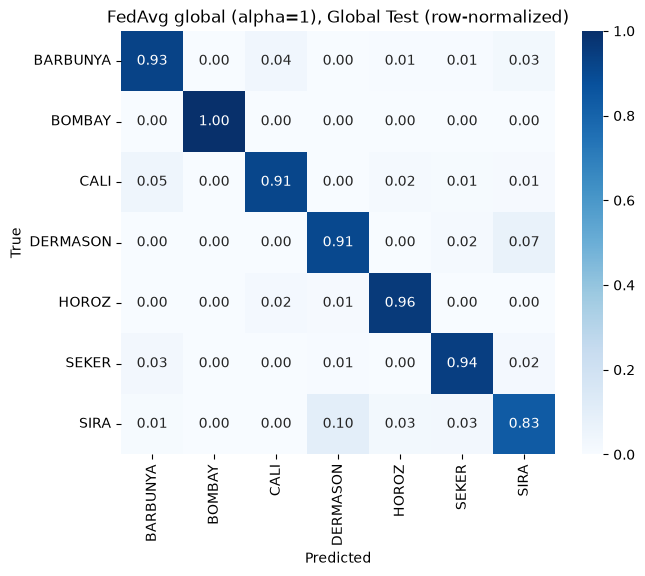

In [40]:
plot_confusion(y_test, predict(X_test, W_fed, b_fed), 'FedAvg global (alpha=1), Global Test (row-normalized)')

**Висновок.**
- **Локальні моделі** значно гірші: macro-F1 від 0.733 до 0.907. Найгірший - клієнт 3 (macro-F1 0.733, log-loss 1.03),
  хоча в нього найбільше даних (2 656)! Причина - у нього лише **1** `CALI` (з ~1 140 у пулі), тож модель майже не вміє розпізнавати
  цей клас. Клієнт 2 (лише 3 `BARBUNYA`) - 0.841. Тобто важить не тільки кількість даних, а й те, які класи є.
- **Глобальна FedAvg** (macro-F1 **0.925**, accuracy 0.912) краща за **кожну** локальну модель і майже дорівнює
  **централізованій** (0.928, accuracy 0.914) - різниця лише 0.003.
- Порівняння матриць помилок: FedAvg трохи гірше впізнає `CALI` (0.91 проти 0.96) і `SIRA` (0.83 проти 0.87),
  але краще `BARBUNYA` (0.93 проти 0.89) - агрегація дещо зсунула межі між близькими класами.

Висновок: об'єднуючи лише **ваги**, клієнти отримують модель майже такої ж якості, як якби вони злили всі дані в одне місце.

### 6.2 Експеримент 1: вплив неоднорідності даних ($\alpha$)

Запускаємо FedAvg з однаковими налаштуваннями ($K = 5$, $E = 5$, 50 раундів) на чотирьох розподілах:
IID, $\alpha$ = 5, $\alpha$ = 1, $\alpha$ = 0.3. Для кожного також навчаємо локальні моделі, щоб знати найкращу й найгіршу з них.

In [41]:
ALPHAS = ['IID', 5, 1, 0.3]
alpha_rows, alpha_histories = [], {}
for alpha in ALPHAS:
    clients = make_clients(splits[alpha])
    W, b, history = run_fedavg(clients, ROUNDS, E_MAIN)
    alpha_histories[alpha] = history
    local_f1 = [evaluate(X_test, y_test, W_k, b_k)['macro_f1'] for W_k, b_k in train_local_models(clients)]
    alpha_rows.append({'split': str(alpha), **evaluate(X_test, y_test, W, b),
                       'best local macro_f1': max(local_f1), 'worst local macro_f1': min(local_f1)})

alpha_table = pd.DataFrame(alpha_rows).set_index('split')
alpha_table.round(4)

,accuracy,macro_f1,balanced_acc,log_loss,best local macro_f1,worst local macro_f1
split,,,,,,
IID,0.9163,0.9290,0.9291,0.2292,0.9274,0.9243
5,0.9163,0.9283,0.9286,0.2298,0.9271,0.9121
1,0.9124,0.9250,0.9271,0.2362,0.9065,0.7334
0.3,0.9144,0.9261,0.9250,0.2445,0.8947,0.5479


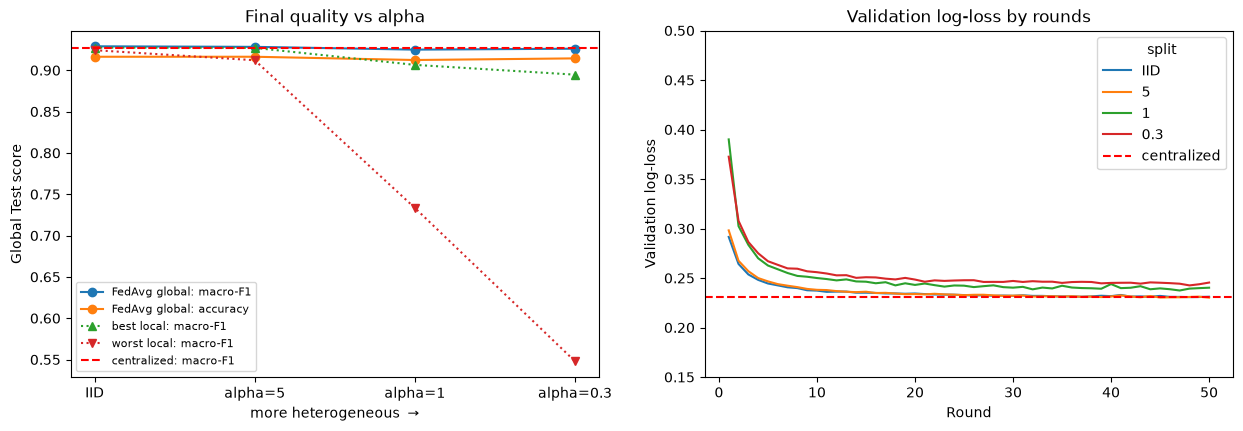

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = range(len(ALPHAS))
axes[0].plot(x, alpha_table['macro_f1'], marker='o', label='FedAvg global: macro-F1')
axes[0].plot(x, alpha_table['accuracy'], marker='o', label='FedAvg global: accuracy')
axes[0].plot(x, alpha_table['best local macro_f1'], marker='^', linestyle=':', label='best local: macro-F1')
axes[0].plot(x, alpha_table['worst local macro_f1'], marker='v', linestyle=':', label='worst local: macro-F1')
axes[0].axhline(central_test['macro_f1'], color='red', linestyle='--', label='centralized: macro-F1')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(['IID', 'alpha=5', 'alpha=1', 'alpha=0.3'])
axes[0].set_xlabel('more heterogeneous  ->')
axes[0].set_ylabel('Global Test score')
axes[0].legend(fontsize=8)
axes[0].set_title('Final quality vs alpha')

for alpha in ALPHAS:
    axes[1].plot(range(1, ROUNDS + 1), alpha_histories[alpha]['val_loss'], label=str(alpha))
axes[1].axhline(central_history['val_loss'][-1], color='red', linestyle='--', label='centralized')
axes[1].set_xlabel('Round')
axes[1].set_ylabel('Validation log-loss')
axes[1].set_ylim(0.15, 0.5)
axes[1].legend(title='split')
axes[1].set_title('Validation log-loss by rounds')
plt.show()

**Висновок.**

| | IID | $\alpha$ = 5 | $\alpha$ = 1 | $\alpha$ = 0.3 |
|---|---|---|---|---|
| macro-F1 глобальної | 0.929 | 0.928 | 0.925 | 0.926 |
| log-loss глобальної | 0.229 | 0.230 | 0.236 | 0.245 |
| найгірша локальна (macro-F1) | 0.924 | 0.912 | 0.733 | 0.548 |

- Що менше $\alpha$ (сильніша неоднорідність), то **гірший log-loss** глобальної моделі (0.229 -> 0.245, тобто на ~7%) і повільніше
  вона вчиться (на правому графіку криві $\alpha$ = 1 та $\alpha$ = 0.3 вищі за IID на всіх раундах і не доходять до лінії централізованої моделі).
  За F1 різниця маленька (0.929 -> 0.926).
- Локальні моделі страждають набагато сильніше: найгірша падає з 0.924 (IID) до **0.548** ($\alpha$ = 0.3), бо клієнти без
  деяких класів просто не можуть їх передбачати.

**Чому Non-IID погіршує FL?** Кожен клієнт мінімізує *свої* втрати, оптимум яких лежить в іншому місці, ніж оптимум
для всіх даних. Під час $E$ локальних епох моделі розходяться до своїх оптимумів, і середнє цих моделей уже не є
точним кроком до спільного оптимуму. Це додає похибку, яка не зникає навіть з кількістю раундів.

**Чи може глобальна модель бути гіршою за централізовану?** Так - при помітній неоднорідності ($\alpha$ = 1 і $\alpha$ = 0.3) вона гірша
(test log-loss 0.236 і 0.245 проти 0.232). Різниця маленька, бо логістична регресія - опукла (convex) задача з одним
мінімумом, і всі клієнти "тягнуть" приблизно в одну область. Для нейромереж різниця зазвичай набагато більша.
При IID і $\alpha$ = 5 глобальна модель на тесті навіть трохи **краща** (log-loss 0.229-0.230 проти 0.232) - це рівень випадкового
шуму: централізована модель - це просто останній крок шумного міні-батчевого спуску з lr = 1, тож різниці ~0.003 нічого не значать.

**Чи може глобальна модель бути гіршою за деякі локальні?** На **глобальному** тесті тут - ні: навіть найкраща локальна
(0.895 при $\alpha$ = 0.3) гірша за глобальну. Але на **власних даних клієнта** - може: модель, навчена лише на "своєму" наборі
класів, краще знає цей набір, ніж глобальний компроміс. Також глобальна модель може бути гіршою за найкращу локальну,
якщо в одного клієнта майже всі дані й вони схожі на тест, а інші клієнти маленькі й "шумні" (особливо при агрегації без
зважування). Саме тому існує персоналізація (експеримент Б, ми його не виконували).

**Зважена vs незважена агрегація** на найбільш неоднорідному розподілі ($\alpha$ = 0.3), де розміри клієнтів найбільше відрізняються:

In [43]:
clients_03 = make_clients(splits[0.3])
print('Client sizes (alpha=0.3):', [len(c['X']) for c in clients_03])
weight_rows = []
for weighted in [True, False]:
    W, b, history = run_fedavg(clients_03, ROUNDS, E_MAIN, weighted=weighted)
    weight_rows.append({'aggregation': 'weighted by n_k' if weighted else 'simple mean',
                        **evaluate(X_test, y_test, W, b)})
pd.DataFrame(weight_rows).set_index('aggregation').round(4)

Client sizes (alpha=0.3): [1505, 1536, 1316, 1046, 4076]


,accuracy,macro_f1,balanced_acc,log_loss
aggregation,,,,
weighted by n_k,0.9144,0.9261,0.9250,0.2445
simple mean,0.9109,0.9247,0.9267,0.2464


**Висновок.** При $\alpha$ = 0.3 клієнт 5 має 43% усіх даних. Зі зважуванням його модель важить 0.43, з простим середнім - лише 0.2.
Наслідок: з простим середнім accuracy падає (0.914 -> 0.911), macro-F1 теж трохи (0.926 -> 0.925) і log-loss гіршає
(0.245 -> 0.246), бо великий клієнт тримає більшість `DERMASON` - найбільшого класу. А balanced accuracy трохи
зросла (0.925 -> 0.927), бо маленькі клієнти тримають рідкісні класи (`BOMBAY`, `BARBUNYA`) і отримали більше ваги.
Ці різниці (0.002-0.004) отримані з одного запуску і близькі до рівня шуму, тому важливіший напрямок, ніж точні числа.
Загалом зважування за $n_k$ відтворює ціль централізованого навчання (середні втрати по всіх прикладах), тому воно
правильніше. Тут різниця невелика, бо навіть найменший клієнт має 1 046 прикладів; при клієнтах з 10-50 прикладами
просте середнє дало б їхнім шумним моделям такий самий голос, як клієнту з тисячами прикладів, і різниця була б помітною.

**Перевірка відтворюваності:** повторний запуск основної конфігурації ($\alpha$ = 1, E = 5) має дати рівно ті самі ваги.

In [44]:
W_again, b_again, _ = run_fedavg(make_clients(make_split(ALPHA_MAIN)), ROUNDS, E_MAIN)
assert np.allclose(W_again, W_fed) and np.allclose(b_again, b_fed)
print('OK: identical result on re-run')

OK: identical result on re-run


### 6.3 Експеримент 2: вплив кількості локальних епох (E)

Порівнюємо $E = 1, 5, 10$ при **однаковій кількості раундів** (50), тобто при однаковій кількості "сеансів зв'язку"
з сервером. Робимо це на сильно неоднорідних даних ($\alpha$ = 0.3), де дрейф має бути помітним, і на IID для контрасту.

In [45]:
E_VALUES = [1, 5, 10]
epoch_rows, epoch_histories = [], {}
for split_name in ['IID', 0.3]:
    clients = make_clients(splits[split_name])
    for E in E_VALUES:
        W, b, history = run_fedavg(clients, ROUNDS, E)
        epoch_histories[(split_name, E)] = history
        epoch_rows.append({'split': str(split_name), 'E': E, **evaluate(X_test, y_test, W, b),
                           'mean drift': np.mean(history['drift']),
                           'val macro_f1 after round 1': history['val_macro_f1'][0]})

epoch_table = pd.DataFrame(epoch_rows).set_index(['split', 'E'])
epoch_table.round(4)

accuracy  macro_f1  balanced_acc  log_loss  mean drift  \
split E                                                            
IID   1     0.9173    0.9295        0.9294    0.2347      0.2937   
      5     0.9163    0.9290        0.9291    0.2292      0.6656   
      10    0.9178    0.9301        0.9299    0.2282      0.9381   
0.3   1     0.9154    0.9262        0.9243    0.2478      1.0827   
      5     0.9144    0.9261        0.9250    0.2445      1.7090   
      10    0.9183    0.9298        0.9291    0.2434      2.0145   

          val macro_f1 after round 1  
split E                               
IID   1                       0.9135  
      5                       0.9259  
      10                      0.9289  
0.3   1                       0.8217  
      5                       0.8976  
      10                      0.9060

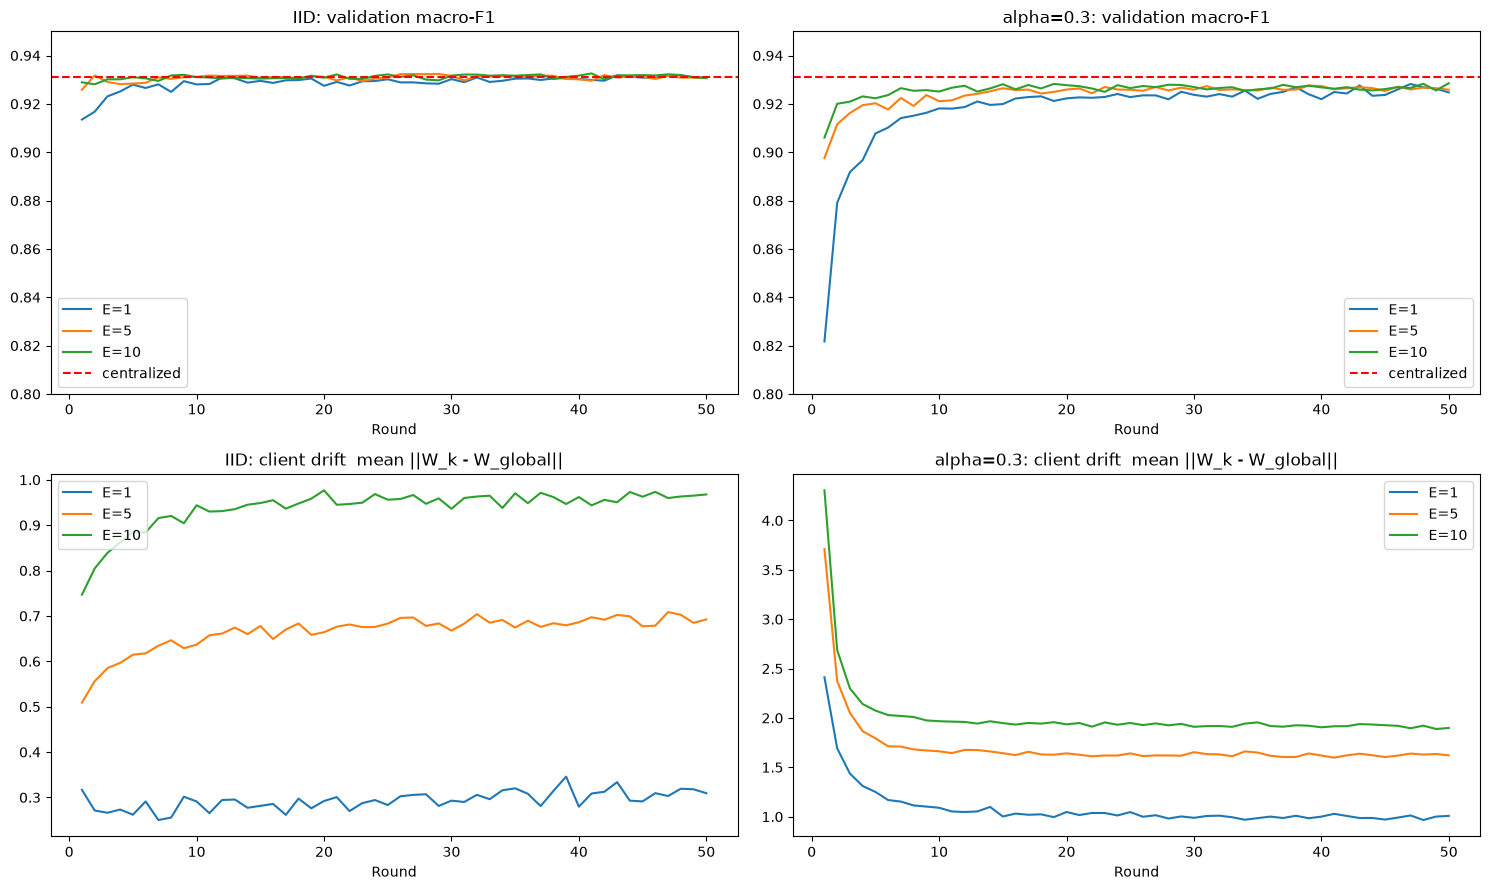

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for col, split_name in enumerate(['IID', 0.3]):
    for E in E_VALUES:
        history = epoch_histories[(split_name, E)]
        axes[0, col].plot(range(1, ROUNDS + 1), history['val_macro_f1'], label=f'E={E}')
        axes[1, col].plot(range(1, ROUNDS + 1), history['drift'], label=f'E={E}')
    title = 'IID' if split_name == 'IID' else f'alpha={split_name}'
    axes[0, col].set_title(f'{title}: validation macro-F1')
    axes[0, col].axhline(central_val['macro_f1'], color='red', linestyle='--', label='centralized')
    axes[1, col].set_title(f'{title}: client drift  mean ||W_k - W_global||')
    for row in range(2):
        axes[row, col].set_xlabel('Round')
        axes[row, col].legend()
axes[0, 0].set_ylim(0.8, 0.95)
axes[0, 1].set_ylim(0.8, 0.95)
plt.tight_layout()
plt.show()

**Висновок.**

| | E = 1 | E = 5 | E = 10 |
|---|---|---|---|
| IID: середній дрейф | 0.29 | 0.67 | 0.94 |
| $\alpha$ = 0.3: середній дрейф | 1.08 | 1.71 | 2.01 |
| $\alpha$ = 0.3: val macro-F1 після 1-го раунду | 0.822 | 0.898 | 0.906 |
| $\alpha$ = 0.3: test macro-F1 після 50 раундів | 0.926 | 0.926 | 0.930 |

**Клієнтський дрейф (client drift)** - це коли під час локального навчання моделі клієнтів відходять від глобальної моделі
кожна в бік оптимуму *своїх* даних. Нижні графіки показують це числом:
- дрейф **росте з E** - більше локальних кроків, далі відходить модель;
- при Non-IID ($\alpha$ = 0.3) дрейф у **2-3.7 рази більший**, ніж при IID з тим самим E, бо клієнти тягнуть у різні боки;
- в IID клієнти рухаються майже в одному напрямку, тому навіть великий E нічого не псує - усі криві доходять до лінії
  централізованої моделі.

Більший E дає **швидший старт** (після 1-го раунду 0.906 при E = 10 проти 0.822 при E = 1): за один "сеанс зв'язку"
клієнт робить більше роботи. Але при $\alpha$ = 0.3 усі криві на **validation** зупиняються на ~0.925-0.929 - **нижче** централізованої
лінії (0.931) - і далі не ростуть (на тесті E = 10 дав 0.930, трохи вище за централізовану 0.928, - це в межах шуму). Це і є ціна дрейфу: середнє розбіжних моделей сходиться не точно в спільний оптимум.

**Чому великий E може погіршувати глобальну модель?** Якщо локальних епох дуже багато, кожен клієнт майже доходить до свого
власного оптимуму, і сервер усереднює моделі, які "знають" лише свої класи. Усереднення таких моделей може бути гіршим,
ніж частіша синхронізація. **У нашому експерименті погіршення від E = 10 не видно** (навіть трохи краще: 0.930), хоча дрейф
виріс удвічі. Причина: логістична регресія опукла і проста (77 параметрів), локальні оптимуми не надто далеко один від одного,
а кожен клієнт має тисячу+ прикладів. На складніших моделях (нейромережі) або при ще меншому $\alpha$ (0.1) ефект був би сильнішим.

---
## 7. Етап 7. Додатковий експеримент А: вплив кількості клієнтів

Фіксуємо $\alpha$ = 1, E = 5, 50 раундів і змінюємо кількість клієнтів: $K = 3, 5, 10$.

In [47]:
k_rows = []
for n_clients in [3, 5, 10]:
    indices_list = make_split(ALPHA_MAIN, K=n_clients)
    sizes = [len(idx) for idx in indices_list]
    W, b, history = run_fedavg(make_clients(indices_list), ROUNDS, E_MAIN)
    k_rows.append({'K': n_clients, 'min client size': min(sizes), 'max client size': max(sizes),
                   **evaluate(X_test, y_test, W, b), 'mean drift': np.mean(history['drift'])})

k_table = pd.DataFrame(k_rows).set_index('K')
k_table.round(4)

,min client size,max client size,accuracy,macro_f1,balanced_acc,log_loss,mean drift
K,,,,,,,
3,2553,4080,0.9129,0.9257,0.9261,0.2342,1.2364
5,1240,2656,0.9124,0.9250,0.9271,0.2362,1.2307
10,433,1564,0.9208,0.9326,0.9319,0.2266,1.0488


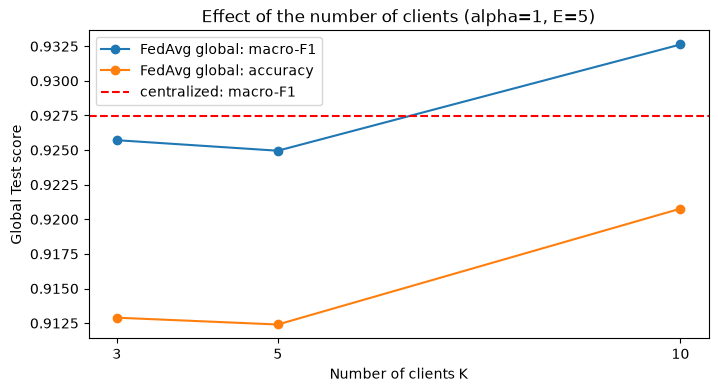

In [48]:
plt.figure(figsize=(8, 4))
plt.plot(k_table.index, k_table['macro_f1'], marker='o', label='FedAvg global: macro-F1')
plt.plot(k_table.index, k_table['accuracy'], marker='o', label='FedAvg global: accuracy')
plt.axhline(central_test['macro_f1'], color='red', linestyle='--', label='centralized: macro-F1')
plt.xticks(k_table.index)
plt.xlabel('Number of clients K')
plt.ylabel('Global Test score')
plt.title('Effect of the number of clients (alpha=1, E=5)')
plt.legend()
plt.show()

**Висновок.** Зі збільшенням K кожен клієнт отримує менше даних: найменший клієнт - 2 553 (K = 3), 1 240 (K = 5), 433 (K = 10).
Очікувано, якість мала б трохи падати (менше даних у кожного -> шумніші локальні моделі). Але тут результати майже
однакові: macro-F1 0.926 / 0.925 / **0.933**, і при K = 10 навіть найкраща, а дрейф найменший (1.05 проти 1.23).

Пояснення: одна локальна епоха - це $n_k / 64$ кроків. У маленького клієнта (433 приклади) це ~7 кроків, у великого
(2 656) - ~40. Тому маленькі клієнти за раунд відходять від глобальної моделі менше, а усереднення 10 моделей сильніше
згладжує шум. До того ж для кожного K розподіл Діріхле генерується заново, тож частина різниці (0.007) - це просто
випадковість конкретного розбиття; щоб робити впевнений висновок, треба повторити з кількома зернами.
Основний висновок: у діапазоні 3-10 клієнтів FedAvg для цієї задачі працює стабільно.

---
## 8. Теоретичні питання

**1. Чому для багатокласової класифікації використовують softmax?**
Нам потрібно з $C$ довільних чисел (оцінок $z_c$ для кожного класу) отримати $C$ ймовірностей: кожна від 0 до 1, сума = 1.
Softmax робить саме це: експонента робить усі числа додатними, а ділення на суму нормує їх. Крім того, він зберігає
порядок (більше $z$ -> більша ймовірність) і "підсилює" найбільшу оцінку. Для $C = 2$ softmax перетворюється на звичайну
сигмоїду, тобто це пряме узагальнення бінарної логістичної регресії. І він дає дуже простий градієнт разом з
крос-ентропією: $P - Y$.

**2. Чому крос-ентропія є природною функцією втрат для логістичної регресії?**
Модель видає ймовірності класів, тож природно шукати такі ваги, при яких **ймовірність побачити наші справжні мітки**
максимальна (метод максимальної правдоподібності). Логарифм цієї правдоподібності зі знаком мінус і є крос-ентропією
$-\sum Y_{ic}\log P_{ic}$. Вона сильно штрафує впевнені помилки ($-\log$ малої ймовірності -> дуже велике число),
вона опукла для логістичної регресії (один мінімум, градієнтний спуск його знайде) і дає простий градієнт
$\frac{1}{m}X^\top(P-Y)$. MSE з сигмоїдою/softmax натомість неопукла і має дуже малі градієнти при впевнених помилках.

**3. Чим відрізняється Ridge-регуляризація від Lasso?**
Ridge (L2) додає $\frac{\lambda}{2}\sum w^2$ - штраф росте квадратично, тому великі ваги зменшуються сильно,
а малі майже не чіпаються; ваги стають маленькими, але **не нульовими**. Добре працює з мультиколінеарністю
(розподіляє вагу між схожими ознаками). Lasso (L1) додає $\lambda\sum|w|$ - штраф однаковий для всіх ваг за модулем,
тому малі ваги "дотискаються" **рівно до нуля**: Lasso одночасно робить відбір ознак. Мінус Lasso - недиференційовний
у нулі і з групи корельованих ознак випадково обирає одну.

**4. Чому параметр зміщення b зазвичай не регуляризують?**
Регуляризація бореться зі складністю моделі - з тим, наскільки сильно передбачення залежить від ознак. Зміщення $b$
не множиться на жодну ознаку, воно лише зсуває рівень (у нас - "базову" схильність до кожного класу, пов'язану з його
частотою). Від нього модель не стає складнішою, а штраф на $b$ змусив би модель ігнорувати реальний дисбаланс класів
і зробив би результат залежним від того, де знаходиться нуль на шкалі ознак.

**5. Що таке Data Leakage?**
Витік даних - це коли під час навчання (включно з підготовкою даних) модель отримує інформацію, якої в неї не було б
у реальному використанні, найчастіше - з тестових даних. Приклади: масштабування чи вибір ознак по всьому датасету
до розбиття, однакові рядки в train і test, ознаки, що "знають" відповідь. Результат - занадто оптимістична оцінка
якості, яка не повториться на нових даних. У цій роботі ми ділили дані першими, видалили дублікати до розбиття,
а кореляції, F-статистику, $\mu$ і $\sigma$ рахували тільки на FL Train Pool.

**6. Чому тестову вибірку не можна використовувати для підбору гіперпараметрів?**
Якщо обирати lr, $\lambda$ чи батч за результатом на тесті, ми підганяємо модель під саме ці 2 032 приклади. Тест
перестає бути "новими" даними, і його оцінка стає завищеною - ми фактично вчимося на тесті через вибір гіперпараметрів.
Для вибору є Global Validation, а тест використовується **один раз** у кінці, щоб чесно оцінити те, що ми обрали.

**7. Чому параметри масштабування потрібно навчати лише на тренувальних даних?**
$\mu$ і $\sigma$ - це теж параметри, які "вчаться" з даних. У реальному житті нові дані приходять по одному, і ми
не знаємо їхнього середнього наперед. Якщо порахувати $\mu, \sigma$ з тестом, інформація про тест потрапляє в
навчання (витік даних). Тому рахуємо на train і застосовуємо ті самі числа до validation і test - саме тому
середнє validation після масштабування не рівно 0 (розділ 1.5).

**8. Що таке федеративне навчання і які його основні переваги?**
Федеративне навчання (federated learning) - спосіб навчити одну спільну модель на даних, розкиданих між багатьма
учасниками, **не збираючи ці дані в одному місці**. Клієнти вчаться локально і надсилають на сервер лише параметри
моделі, сервер їх усереднює і розсилає назад. Переваги: приватність (сирі дані не покидають клієнта - лікарні,
телефони, банки), відповідність законам про дані, менше передачі великих обсягів даних, можливість використати дані,
які інакше не можна було б об'єднати. У нашій роботі FedAvg дав macro-F1 0.925 проти 0.928 у централізованої моделі.

**9. Чому сервер не повинен отримувати сирі дані клієнтів?**
Бо вся ідея FL - у збереженні приватності: дані можуть бути медичними, фінансовими чи особистими, і закон або
домовленість забороняє їх передавати. Якщо сервер отримує сирі дані, це вже звичайне централізоване навчання з усіма
ризиками (витік, злам сервера, зловживання). Крім того, сервер у нашій схемі тримає Global Validation і Test - якщо
дані клієнтів змішаються з ними, оцінка стає нечесною.

**10. Чому агрегація ваг за методом FedAvg використовує зважування за кількістю прикладів?**
Бо мета - та сама, що в централізованому навчанні: мінімізувати середні втрати по **всіх прикладах**
$\frac{1}{N}\sum_i \ell_i = \sum_k \frac{n_k}{N}L_k$. У цій сумі кожен клієнт уже має вагу $n_k/N$. До того ж
модель, навчена на більшій кількості прикладів, - надійніша, тож справедливо дати їй більший вплив.

**11. Що станеться, якщо агрегувати параметри клієнтів без зважування?**
Кожен клієнт отримає однаковий вплив $1/K$ незалежно від розміру. Маленькі клієнти з шумними моделями (і часто лише
кількома класами) зсунуть глобальну модель у свій бік, а великий клієнт буде "недопредставлений". У нашому експерименті
($\alpha$ = 0.3, клієнт 5 має 43% даних, але отримав 20% ваги) accuracy впала з 0.914 до 0.911, а log-loss зріс з 0.245 до 0.246.
Різниця маленька, бо всі клієнти мають понад 1 000 прикладів; при дуже нерівних розмірах вона була б більшою.
В IID з однаковими клієнтами різниці немає зовсім.

**12. Що таке Non-IID дані?**
IID - незалежні й однаково розподілені: кожен клієнт має дані з того самого розподілу, що й усі разом. Non-IID - коли
розподіли в клієнтів різні: інша частка класів (як у нас з Діріхле - у клієнта 4 при $\alpha$ = 0.3 немає `DERMASON`),
інші значення ознак (різні камери, різні регіони), різний обсяг даних. У реальних FL-системах дані майже завжди Non-IID.

**13. Чому федеративне навчання може погіршуватися на Non-IID даних?**
Кожен клієнт мінімізує свої втрати, оптимум яких лежить не там, де оптимум для всіх даних. За кілька локальних епох
моделі розходяться в різні боки (дрейф), і середнє розбіжних моделей - це не те саме, що крок градієнтного спуску на
всіх даних. Тому навчання повільніше і може зупинитися не в найкращій точці. У нас: log-loss 0.229 (IID) проти 0.245
($\alpha$ = 0.3), а при $\alpha$ = 0.3 криві навчання стоять нижче лінії централізованої моделі.

**14. Що таке клієнтський дрейф (client drift)?**
Це відхилення локальних моделей від глобальної під час локального навчання: кожен клієнт "тягне" ваги до оптимуму своїх
даних. Ми міряли його як середню відстань $\|W_k - W_{global}\|_F$: при $\alpha$ = 0.3 він у 2-3.7 рази більший, ніж при IID,
і росте з кількістю локальних епох (1.08 -> 2.01 для E = 1 -> 10).

**15. Як кількість локальних епох впливає на глобальну модель?**
Більше E - більше роботи за один раунд, тому глобальна модель вчиться швидше на перших раундах і потрібно менше
сеансів зв'язку (у нас після 1-го раунду 0.906 при E = 10 проти 0.822 при E = 1). Але більше E - і більший дрейф: на
Non-IID даних моделі клієнтів сильніше розходяться, і їхнє середнє може бути гіршим. Тобто E - компроміс між
швидкістю/вартістю зв'язку і точністю. У нашій простій опуклій задачі погіршення від E = 10 не з'явилось, але дрейф подвоївся.

**16. Чи може глобальна модель бути гіршою за централізовану модель? Чому?**
Так, і зазвичай вона хоч трохи гірша. Централізована модель бачить усі дані на кожному кроці; FedAvg бачить їх лише
через усереднення моделей, навчених окремо, і на Non-IID даних має дрейф. В IID і при слабкій неоднорідності ($\alpha$ = 5) вони
майже однакові (у нас macro-F1 0.929 / 0.928 проти 0.928 - різниця в межах шуму), а при помітній неоднорідності
($\alpha$ = 1 і 0.3) глобальна гірша (log-loss 0.236-0.245 проти 0.232).
Для складніших моделей різниця зазвичай більша.

**17. Які метрики краще використовувати для багатокласової класифікації з можливим дисбалансом класів?**
Accuracy при дисбалансі вводить в оману: модель, яка добре знає великі класи і погано маленькі, все одно матиме
високу accuracy. Краще дивитися на **macro-F1** (F1 кожного класу, потім просте середнє - кожен клас важить однаково),
**balanced accuracy** (середній recall по класах), **confusion matrix** (видно, які саме класи плутаються), а для
ймовірностей - **log-loss**. Корисні також MCC і per-class precision/recall. У нас accuracy 0.914, а macro-F1 0.928 -
різниця якраз через те, що найбільші класи `DERMASON` і `SIRA` найважчі.

---
## Висновки

1. **Дані.** Dry Bean: 13 611 зерен, 16 числових ознак, 7 незбалансованих класів (від ~4% до ~26%). Пропусків немає,
   68 дублікатів видалили до розбиття. Дані розділили на FL Train Pool (70%), Global Validation (15%) і Global Test (15%)
   стратифіковано і **до** будь-якої обробки, щоб не було витоку даних.
2. **Ознаки.** Через сильну мультиколінеарність (групи "розмір" і "видовженість", r до 1.00) прибрали 6 дублікатів,
   лишили 10 ознак. Відбір робили лише на FL Train Pool (кореляції + ANOVA F). Стандартизація - за $\mu, \sigma$ з пулу;
   показали, що федеративне обчислення $\mu, \sigma$ з локальних статистик клієнтів дає ті самі числа.
3. **Модель.** Softmax-регресію (softmax з відніманням максимуму, крос-ентропія з Ridge, градієнти, міні-батчевий спуск)
   написано на `numpy` без циклів по прикладах. Градієнти перевірено чисельно (відносна похибка ~$10^{-10}$).
4. **Централізована модель.** На validation обрано lr = 1.0, batch = 64, $\lambda = 0$ (Ridge тут лише шкодить - модель
   не перенавчається). Global Test: accuracy 0.914, macro-F1 0.928, balanced accuracy 0.928, log-loss 0.232.
   Найчастіше плутаються `DERMASON` <-> `SIRA` і `BARBUNYA` -> `CALI`.
5. **Розподіл між клієнтами.** IID і Non-IID (Діріхле з $\alpha$ = 5, 1, 0.3) для 5 клієнтів; кожен приклад рівно в одного клієнта,
   розподіли відтворювані й задокументовані таблицями й тепловими картами. При $\alpha$ = 0.3 деякі клієнти зовсім не мають 2 класів.
6. **FedAvg.** Глобальна модель ($\alpha$ = 1, E = 5, 50 раундів) має macro-F1 0.925 - краще за кожну локальну модель (0.73-0.91)
   і майже як централізована (0.928), хоча сервер не бачив жодного прикладу клієнтів.
7. **Експеримент 1 ($\alpha$).** Сильніша неоднорідність погіршує глобальну модель (log-loss 0.229 -> 0.245, повільніше навчання)
   і дуже сильно погіршує локальні (найгірша 0.92 -> 0.55). Зважування за $n_k$ трохи краще за просте середнє.
8. **Експеримент 2 (E).** Клієнтський дрейф росте з E і в 2-3.7 рази більший на Non-IID даних. Більший E прискорює
   перші раунди, але на Non-IID усі варіанти на validation зупиняються нижче централізованої моделі. Шкоди від E = 10 у нашій простій
   опуклій задачі не видно.
9. **Експеримент А (K).** Для K = 3, 5, 10 якість майже однакова (macro-F1 0.925-0.933) - FedAvg стабільний у цьому діапазоні.'